# Predicción del riesgo de enfermedad coronaria a 10 años mediante Regresión Logística
### Ciclo completo de datos: obtención, extracción, limpieza, modelado predictivo y visualización

**Materia:** Ingeniería del Conocimiento
**Docente:** Rafael Hernandez Lopez
**Integrantes:**
- _Dávila Rodríguez Ángeles_
- _Hernández Fabela Diego Miguel_
- _Johnson Soto Jesús David_
- _López Fonseca Oscar_
- _Renteria Tellez Ana Cecilia_
- _Tarango Regis Luis Antonio_
- _Tellez Enriquez Angelo Armando_

**Fecha:** 19 noviembre 2026

---

**Contenido**

1. Introducción y objetivo
2. Obtención del conjunto de datos
3. Importación de librerías
4. Importación del conjunto de datos (extracción)
5. Análisis exploratorio de datos (EDA)
6. Variables independientes (X) y dependiente (y)
7. División en entrenamiento y prueba
8. Tratamiento de datos faltantes
9. Codificación de datos categóricos
10. Escalado de datos
11. Fundamentos de la Regresión Logística
12. Modelo base
13. Tratamiento del desbalance de clases
14. Selección de variables y optimización del modelo
15. Ajuste del umbral de decisión
16. Evaluación final en el conjunto de prueba
17. Interpretación del modelo (odds ratios)
18. Exportación del modelo y de los datos
19. Conclusiones, limitaciones y recomendaciones
20. Referencias

## 1. Introducción y objetivo

Las enfermedades cardiovasculares son la **principal causa de muerte en el mundo**: de acuerdo con la Organización Mundial de la Salud, provocan cerca de 17.9 millones de defunciones al año. Dentro de ellas, la **enfermedad coronaria** (CHD, *Coronary Heart Disease*) —el estrechamiento de las arterias que irrigan al corazón— es la más frecuente y suele desarrollarse en silencio durante años antes de manifestarse como un infarto.

Gran parte de los factores que la provocan son **modificables** (tabaquismo, presión arterial, colesterol, glucosa, peso), por lo que **identificar a tiempo a las personas con alto riesgo** permite intervenir con cambios de estilo de vida o tratamiento antes de que ocurra un evento grave.

**Pregunta a resolver**

> A partir de datos demográficos, de comportamiento y clínicos de un paciente, ¿podemos estimar la probabilidad de que desarrolle enfermedad coronaria en los próximos 10 años?

**Objetivo general**

Construir, evaluar e interpretar un modelo de **Regresión Logística** que clasifique a los pacientes según su riesgo de desarrollar enfermedad coronaria a 10 años (`TenYearCHD`), recorriendo el ciclo completo de datos.

**Objetivos específicos**

1. Obtener, describir y comprender el conjunto de datos del Framingham Heart Study.
2. Limpiar y preparar los datos (datos faltantes, codificación, escalado) sin contaminar la evaluación.
3. Entrenar un modelo de Regresión Logística, tratar el desbalance de clases y optimizar sus hiperparámetros.
4. Evaluar el modelo con métricas adecuadas para un problema médico desbalanceado.
5. Interpretar el modelo para identificar los factores de riesgo más importantes.
6. Exportar el modelo y los datos para su uso en un dashboard interactivo.

## 2. Obtención del conjunto de datos

**Fuente:** *Framingham Heart Study*, publicado en Kaggle como *"Logistic regression to predict heart disease"* (archivo `framingham.csv`).

El **Framingham Heart Study** es uno de los estudios epidemiológicos más importantes de la historia de la medicina. Inició en **1948** en la ciudad de **Framingham, Massachusetts (EE. UU.)**, a cargo del *National Heart, Lung, and Blood Institute* (NHLBI), y ha dado seguimiento a varias generaciones de habitantes. Gracias a él se acuñó el concepto de **"factor de riesgo"** y se demostró la relación entre tabaquismo, hipertensión y colesterol con las enfermedades del corazón.

El conjunto de datos contiene **4,238 registros** (pacientes) y **16 variables**: 15 posibles predictores y la variable objetivo.

### Diccionario de datos

| Variable | Descripción | Tipo | Unidad / valores |
|---|---|---|---|
| `male` | Sexo del paciente | Binaria (demográfica) | 1 = hombre, 0 = mujer |
| `age` | Edad al momento del examen | Numérica continua | años |
| `education` | Nivel educativo | Categórica ordinal | 1 = preparatoria incompleta, 2 = preparatoria, 3 = estudios técnicos / universidad incompleta, 4 = universidad |
| `currentSmoker` | Fumador actual | Binaria (comportamiento) | 1 = sí, 0 = no |
| `cigsPerDay` | Cigarrillos fumados al día (promedio) | Numérica | cigarrillos / día |
| `BPMeds` | Toma medicamento para la presión arterial | Binaria (historial médico) | 1 = sí, 0 = no |
| `prevalentStroke` | Ha sufrido un derrame cerebral | Binaria (historial médico) | 1 = sí, 0 = no |
| `prevalentHyp` | Es hipertenso | Binaria (historial médico) | 1 = sí, 0 = no |
| `diabetes` | Tiene diabetes | Binaria (historial médico) | 1 = sí, 0 = no |
| `totChol` | Colesterol total | Numérica continua | mg/dL (deseable < 200) |
| `sysBP` | Presión arterial sistólica | Numérica continua | mmHg (normal < 120) |
| `diaBP` | Presión arterial diastólica | Numérica continua | mmHg (normal < 80) |
| `BMI` | Índice de masa corporal | Numérica continua | kg/m² (normal 18.5 – 24.9) |
| `heartRate` | Frecuencia cardiaca en reposo | Numérica continua | latidos / min (normal 60 – 100) |
| `glucose` | Glucosa en sangre | Numérica continua | mg/dL (normal en ayuno 70 – 100) |
| **`TenYearCHD`** | **Desarrolló enfermedad coronaria en los siguientes 10 años** | **Binaria (objetivo)** | **1 = sí, 0 = no** |

Se trata de un problema de **clasificación binaria supervisada**, por lo que la **Regresión Logística** es un modelo adecuado: además de clasificar, entrega una **probabilidad** y sus coeficientes son **interpretables**.

## 3. Importación de librerías

Se importan las librerías base para manipulación de datos (`numpy`, `pandas`) y visualización (`matplotlib`, `seaborn`). Las herramientas de `scikit-learn`, `imbalanced-learn` y `statsmodels` se importan en la sección donde se utilizan, para dejar claro el propósito de cada una.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.0)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

RANDOM_STATE = 0                      # semilla para reproducibilidad
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

def guardar_figura(nombre):
    # Guarda la figura actual en la carpeta figures/ (se reutiliza en la presentación)
    plt.savefig(FIG_DIR / f'{nombre}.png', dpi=150, bbox_inches='tight')

COLOR_SANO, COLOR_CHD = '#4C72B0', '#C44E52'

## 4. Importación del conjunto de datos (extracción)

Se carga el archivo CSV original desde `data/raw/` y se realiza una primera inspección: dimensiones, tipos de datos, estadísticas descriptivas, duplicados y datos faltantes.

In [2]:
dataset = pd.read_csv('data/raw/framingham.csv')
dataset.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.000,0,0.000,0.000,0,0,0,195.000,106.000,70.000,26.970,80.000,77.000,0
1,0,46,2.000,0,0.000,0.000,0,0,0,250.000,121.000,81.000,28.730,95.000,76.000,0
2,1,48,1.000,1,20.000,0.000,0,0,0,245.000,127.500,80.000,25.340,75.000,70.000,0
3,0,61,3.000,1,30.000,0.000,0,1,0,225.000,150.000,95.000,28.580,65.000,103.000,1
4,0,46,3.000,1,23.000,0.000,0,0,0,285.000,130.000,84.000,23.100,85.000,85.000,0


In [3]:
print('Dimensiones (filas, columnas):', dataset.shape)
dataset.info()

Dimensiones (filas, columnas): (4238, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int

In [4]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
male,"4,238.000",0.429,0.495,0.000,0.000,0.000,1.000,1.000
age,"4,238.000",49.585,8.572,32.000,42.000,49.000,56.000,70.000
education,"4,133.000",1.979,1.020,1.000,1.000,2.000,3.000,4.000
currentSmoker,"4,238.000",0.494,0.500,0.000,0.000,0.000,1.000,1.000
cigsPerDay,"4,209.000",9.003,11.920,0.000,0.000,0.000,20.000,70.000
BPMeds,"4,185.000",0.030,0.170,0.000,0.000,0.000,0.000,1.000
prevalentStroke,"4,238.000",0.006,0.077,0.000,0.000,0.000,0.000,1.000
prevalentHyp,"4,238.000",0.311,0.463,0.000,0.000,0.000,1.000,1.000
diabetes,"4,238.000",0.026,0.158,0.000,0.000,0.000,0.000,1.000
totChol,"4,188.000",236.722,44.590,107.000,206.000,234.000,263.000,696.000


In [5]:
print('Registros duplicados:', dataset.duplicated().sum())

faltantes = pd.DataFrame({
    'faltantes': dataset.isnull().sum(),
    'porcentaje (%)': dataset.isnull().mean() * 100
})
faltantes = faltantes[faltantes['faltantes'] > 0].sort_values('faltantes', ascending=False)
print('Registros con al menos un dato faltante:', dataset.isnull().any(axis=1).sum())
faltantes

Registros duplicados: 0
Registros con al menos un dato faltante: 582


,faltantes,porcentaje (%)
glucose,388,9.155
education,105,2.478
BPMeds,53,1.251
totChol,50,1.180
cigsPerDay,29,0.684
BMI,19,0.448
heartRate,1,0.024


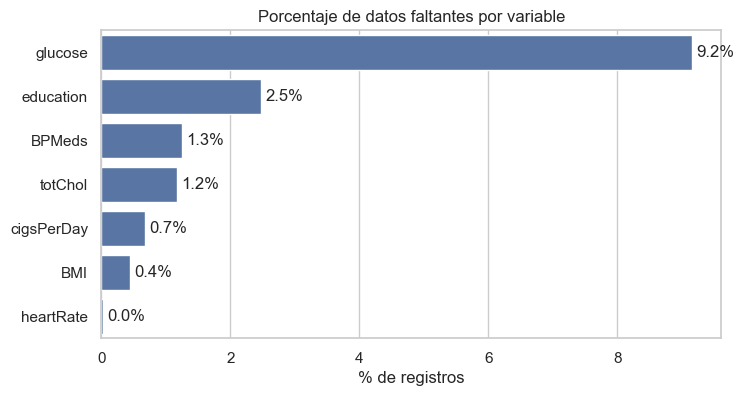

In [6]:
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=faltantes['porcentaje (%)'], y=faltantes.index, color=COLOR_SANO)
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.title('Porcentaje de datos faltantes por variable')
plt.xlabel('% de registros'); plt.ylabel('')
guardar_figura('01_datos_faltantes')
plt.show()

**Observaciones de la extracción** _(ver resultados arriba)_


- El conjunto tiene **4,238 registros y 16 columnas**, todas numéricas (`int64` y `float64`); no hay columnas de texto.
- **No existen registros duplicados.**
- **7 variables tienen datos faltantes.** La más afectada es `glucose`, con 388 registros (9.2 %); las demás tienen menos del 2.5 %.
- **582 registros (13.7 %) tienen al menos un dato faltante.** Eliminarlos implicaría perder casi 1 de cada 7 pacientes, incluidos casos con CHD, que ya son escasos. Por eso se opta por **imputar** en lugar de eliminar (sección 8).
- Las estadísticas descriptivas muestran máximos muy altos en `totChol` (696), `sysBP` (295) y `glucose` (394), que se revisan en la sección 5.6.


## 5. Análisis exploratorio de datos (EDA)

El objetivo de esta sección es **entender los datos antes de modelar**: cómo se distribuye la variable objetivo, qué factores se asocian con la enfermedad coronaria y si existen relaciones fuertes entre las variables.

> El EDA se realiza sobre el conjunto completo únicamente para **describir** los datos; todas las decisiones que "aprenden" de los datos (imputación, escalado, modelo) se toman después **solo con el conjunto de entrenamiento**.

### 5.1 Distribución de la variable objetivo

             pacientes  porcentaje (%)
TenYearCHD                            
Sin CHD (0)       3594          84.804
Con CHD (1)        644          15.196


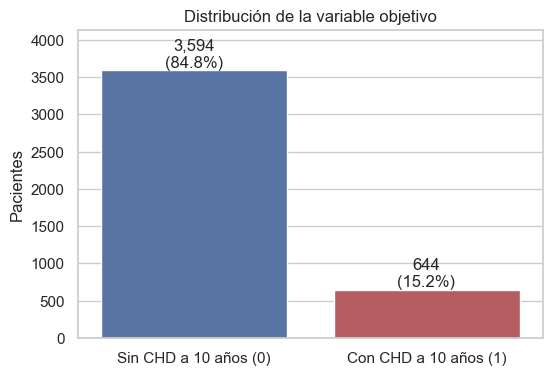

In [7]:
conteo = dataset['TenYearCHD'].value_counts().sort_index()
porc = dataset['TenYearCHD'].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({'pacientes': conteo, 'porcentaje (%)': porc}).rename(index={0: 'Sin CHD (0)', 1: 'Con CHD (1)'}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='TenYearCHD', data=dataset, palette=[COLOR_SANO, COLOR_CHD])
ax.set_xticklabels(['Sin CHD a 10 años (0)', 'Con CHD a 10 años (1)'])
for p, pct in zip(ax.patches, porc):
    ax.annotate(f'{int(p.get_height()):,}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.ylim(0, conteo.max() * 1.15)
plt.title('Distribución de la variable objetivo'); plt.xlabel(''); plt.ylabel('Pacientes')
guardar_figura('02_distribucion_objetivo')
plt.show()


**Interpretación:** solo el **15.2 %** de los pacientes (644) desarrolló enfermedad coronaria en los 10 años siguientes, frente al 84.8 % (3,594) que no. Es un problema **desbalanceado**: hay aproximadamente **5.6 pacientes sanos por cada paciente con CHD**.

Esto tiene una consecuencia directa: un "modelo" que siempre respondiera *"no desarrollará CHD"* acertaría el 84.8 % de las veces y, sin embargo, sería completamente inútil, porque no detectaría a ningún paciente en riesgo. Por eso **la exactitud no es una métrica adecuada** para este problema y será necesario tratar el desbalance (secciones 13 y 15).


### 5.2 Distribución de las variables numéricas según la variable objetivo

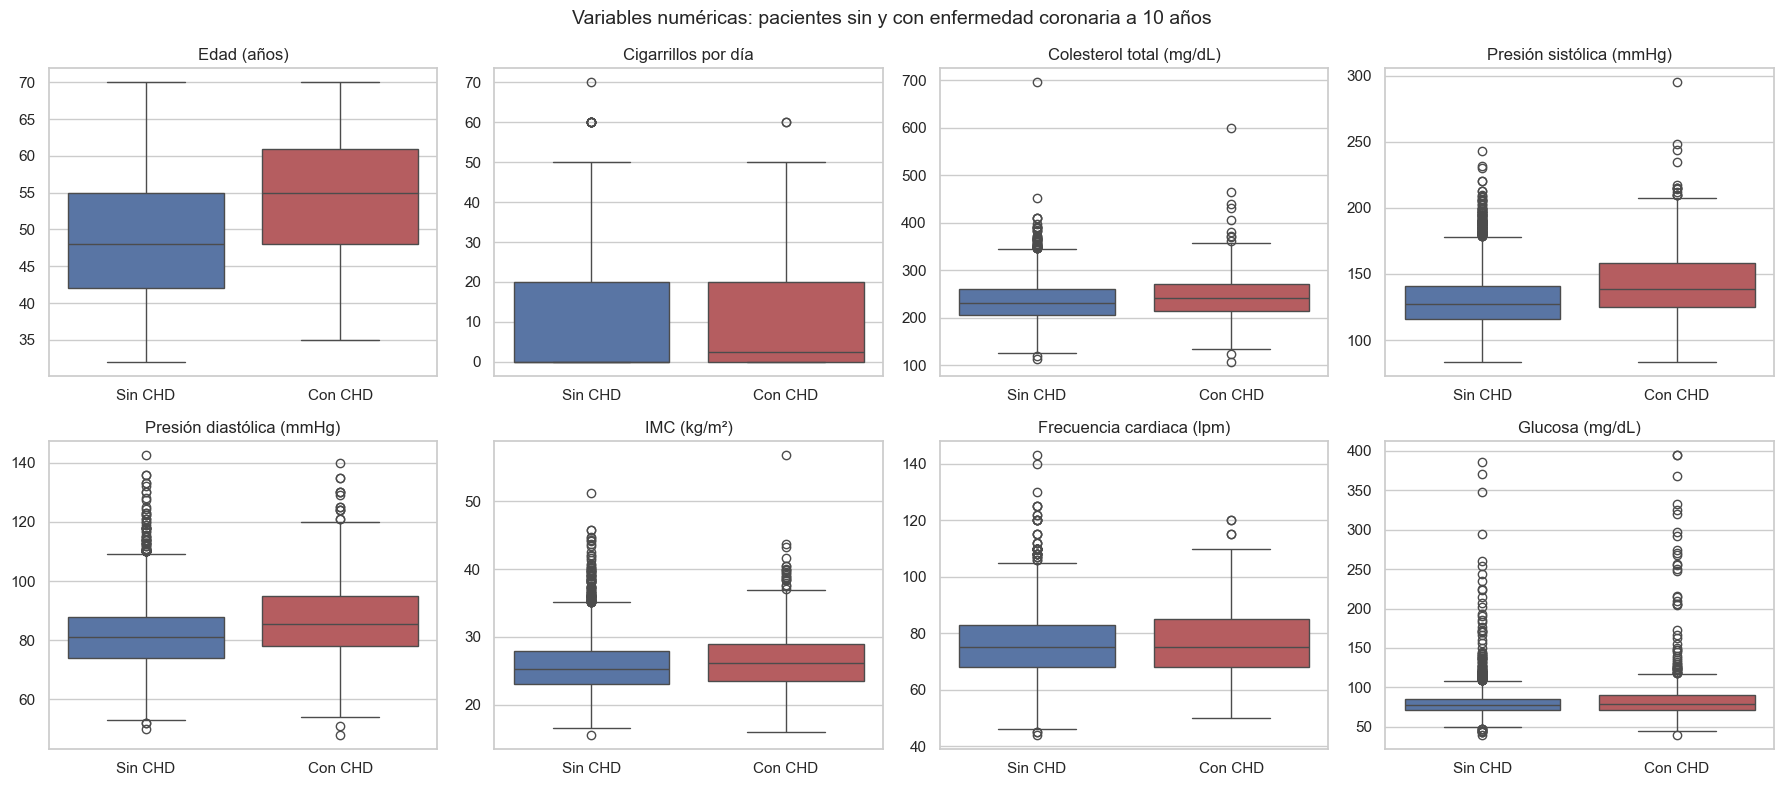

TenYearCHD,Mediana sin CHD,Mediana con CHD
age,48.000,55.000
cigsPerDay,0.000,2.500
totChol,232.000,241.000
sysBP,127.000,139.000
diaBP,81.000,85.500
BMI,25.250,26.155
heartRate,75.000,75.000
glucose,78.000,79.000


In [8]:
numericas = ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
nombres = {'age': 'Edad (años)', 'cigsPerDay': 'Cigarrillos por día', 'totChol': 'Colesterol total (mg/dL)',
           'sysBP': 'Presión sistólica (mmHg)', 'diaBP': 'Presión diastólica (mmHg)', 'BMI': 'IMC (kg/m²)',
           'heartRate': 'Frecuencia cardiaca (lpm)', 'glucose': 'Glucosa (mg/dL)'}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), numericas):
    sns.boxplot(x='TenYearCHD', y=col, data=dataset, ax=ax, palette=[COLOR_SANO, COLOR_CHD])
    ax.set_title(nombres[col]); ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_xticklabels(['Sin CHD', 'Con CHD'])
plt.suptitle('Variables numéricas: pacientes sin y con enfermedad coronaria a 10 años', fontsize=14)
plt.tight_layout()
guardar_figura('03_boxplots_numericas')
plt.show()

dataset.groupby('TenYearCHD')[numericas].median().T.rename(columns={0: 'Mediana sin CHD', 1: 'Mediana con CHD'})


**Interpretación:**
- **Edad:** es la diferencia más marcada. La mediana de los pacientes con CHD es de **55 años**, contra **48** en los que no la desarrollaron.
- **Presión arterial:** la sistólica es claramente mayor en los pacientes con CHD (mediana **139 vs. 127 mmHg**); la diastólica también lo es, aunque en menor medida (85.5 vs. 81).
- **Colesterol e IMC:** son ligeramente mayores en el grupo con CHD (241 vs. 232 mg/dL y 26.2 vs. 25.3 kg/m²), con distribuciones muy traslapadas.
- **Glucosa:** la mediana prácticamente no cambia (79 vs. 78 mg/dL); su relación con el riesgo proviene de los **valores muy elevados**, propios de pacientes con diabetes.
- **Cigarrillos por día:** la mediana del grupo con CHD es mayor (2.5 vs. 0), es decir, hay una mayor proporción de fumadores.
- **Frecuencia cardiaca:** no muestra diferencia (mediana de 75 en ambos grupos), por lo que se espera que aporte poco al modelo.

Ninguna variable separa por sí sola a los dos grupos (las cajas se traslapan), lo que anticipa que el riesgo depende de la **combinación** de varios factores.


### 5.3 Riesgo de enfermedad coronaria por edad

       % con CHD  pacientes
age                        
30-39      4.144        555
40-49     10.060       1660
50-59     19.730       1333
60-70     27.681        690


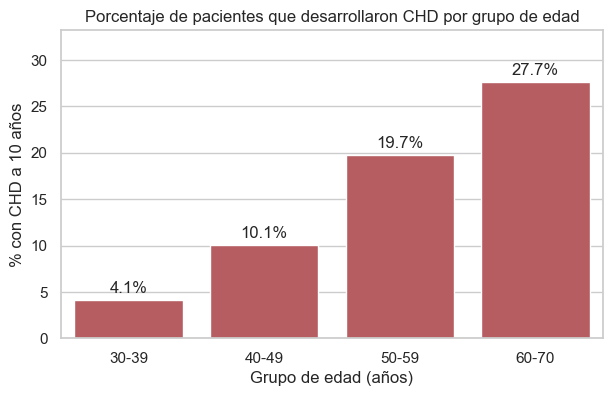

In [9]:
grupos_edad = pd.cut(dataset['age'], bins=[30, 39, 49, 59, 70], labels=['30-39', '40-49', '50-59', '60-70'])
riesgo_edad = dataset.groupby(grupos_edad, observed=True)['TenYearCHD'].agg(['mean', 'count'])
riesgo_edad['mean'] *= 100
riesgo_edad.columns = ['% con CHD', 'pacientes']
print(riesgo_edad)

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=riesgo_edad.index, y=riesgo_edad['% con CHD'], color=COLOR_CHD)
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
plt.title('Porcentaje de pacientes que desarrollaron CHD por grupo de edad')
plt.xlabel('Grupo de edad (años)'); plt.ylabel('% con CHD a 10 años')
plt.ylim(0, riesgo_edad['% con CHD'].max() * 1.2)
guardar_figura('04_riesgo_por_edad')
plt.show()


**Interpretación:** el riesgo crece de forma constante con la edad: pasa de **4.1 %** en el grupo de 30 a 39 años a **27.7 %** en el de 60 a 70. Es decir, casi **7 veces más** riesgo en el grupo de mayor edad. La edad aparece como uno de los factores de riesgo más importantes.


### 5.4 Riesgo de enfermedad coronaria según factores binarios

                     No (0)  Sí (1)  pacientes con el factor  \
factor                                                         
Derrame previo       15.025  44.000                       25   
Diabetes             14.628  36.697                      109   
Medicamento presión  14.578  33.065                      124   
Hipertensión         10.917  24.696                     1316   
Sexo masculino       12.443  18.857                     1819   
Fumador actual       14.506  15.903                     2094   

                     riesgo relativo (Sí / No)  
factor                                          
Derrame previo                           2.928  
Diabetes                                 2.509  
Medicamento presión                      2.268  
Hipertensión                             2.262  
Sexo masculino                           1.515  
Fumador actual                           1.096  


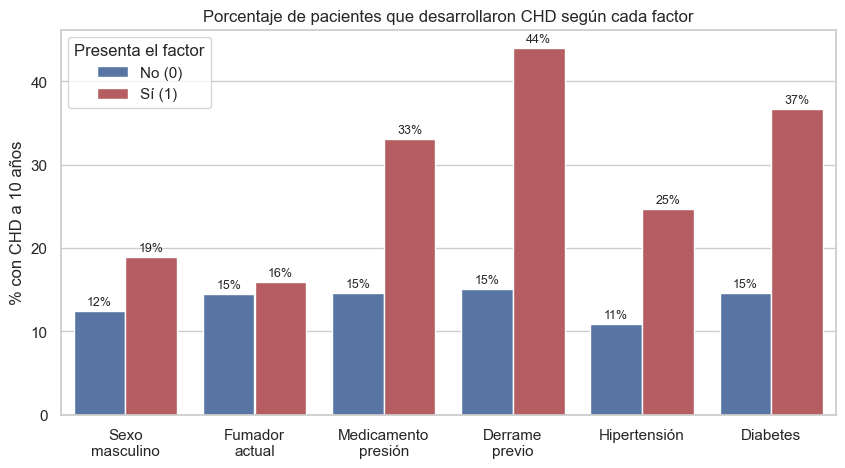

In [10]:
binarias = ['male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes']
nombres_bin = {'male': 'Sexo masculino', 'currentSmoker': 'Fumador actual', 'BPMeds': 'Medicamento presión',
               'prevalentStroke': 'Derrame previo', 'prevalentHyp': 'Hipertensión', 'diabetes': 'Diabetes'}

filas = []
for col in binarias:
    tasas = dataset.groupby(col)['TenYearCHD'].mean() * 100
    filas.append({'factor': nombres_bin[col], 'No (0)': tasas.get(0.0), 'Sí (1)': tasas.get(1.0),
                  'pacientes con el factor': int((dataset[col] == 1).sum())})
riesgo_bin = pd.DataFrame(filas).set_index('factor')
riesgo_bin['riesgo relativo (Sí / No)'] = riesgo_bin['Sí (1)'] / riesgo_bin['No (0)']
print(riesgo_bin.sort_values('riesgo relativo (Sí / No)', ascending=False))

datos_graf = riesgo_bin[['No (0)', 'Sí (1)']].reset_index().melt(id_vars='factor', var_name='Presenta el factor',
                                                                   value_name='% con CHD')
plt.figure(figsize=(10, 5))
ax = sns.barplot(x='factor', y='% con CHD', hue='Presenta el factor', data=datos_graf,
                 palette=[COLOR_SANO, COLOR_CHD])
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f%%', padding=2, fontsize=9)
ax.set_xticklabels([t.get_text().replace(' ', chr(10), 1) for t in ax.get_xticklabels()])
plt.title('Porcentaje de pacientes que desarrollaron CHD según cada factor')
plt.xlabel(''); plt.ylabel('% con CHD a 10 años')
guardar_figura('05_riesgo_factores_binarios')
plt.show()


**Interpretación** (el *riesgo relativo* indica cuántas veces más frecuente es la CHD en quienes tienen el factor):
- **Derrame cerebral previo:** 44 % vs. 15 % (**2.9 veces** más). Es el factor con mayor efecto, pero solo hay **25 pacientes** con este antecedente, así que la estimación es poco precisa.
- **Diabetes:** 36.7 % vs. 14.6 % (**2.5 veces**).
- **Medicamento para la presión:** 33.1 % vs. 14.6 % (**2.3 veces**).
- **Hipertensión:** 24.7 % vs. 10.9 % (**2.3 veces**). Es el factor más relevante **a nivel poblacional**, porque lo presentan 1,316 pacientes (31 %).
- **Sexo masculino:** 18.9 % vs. 12.4 % (**1.5 veces**).
- **Fumador actual:** 15.9 % vs. 14.5 %, una diferencia muy pequeña (**1.1 veces**). Este resultado sorprende, pero tiene explicación: en este conjunto los fumadores tienden a ser **más jóvenes** (correlación edad–fumador = −0.21), y la edad compensa el efecto del tabaco. Además, más que el hecho de fumar, importa **cuánto** se fuma (`cigsPerDay`). Esto muestra por qué hay que analizar los factores **en conjunto**, que es justamente lo que hace la Regresión Logística.


### 5.5 Correlación entre variables

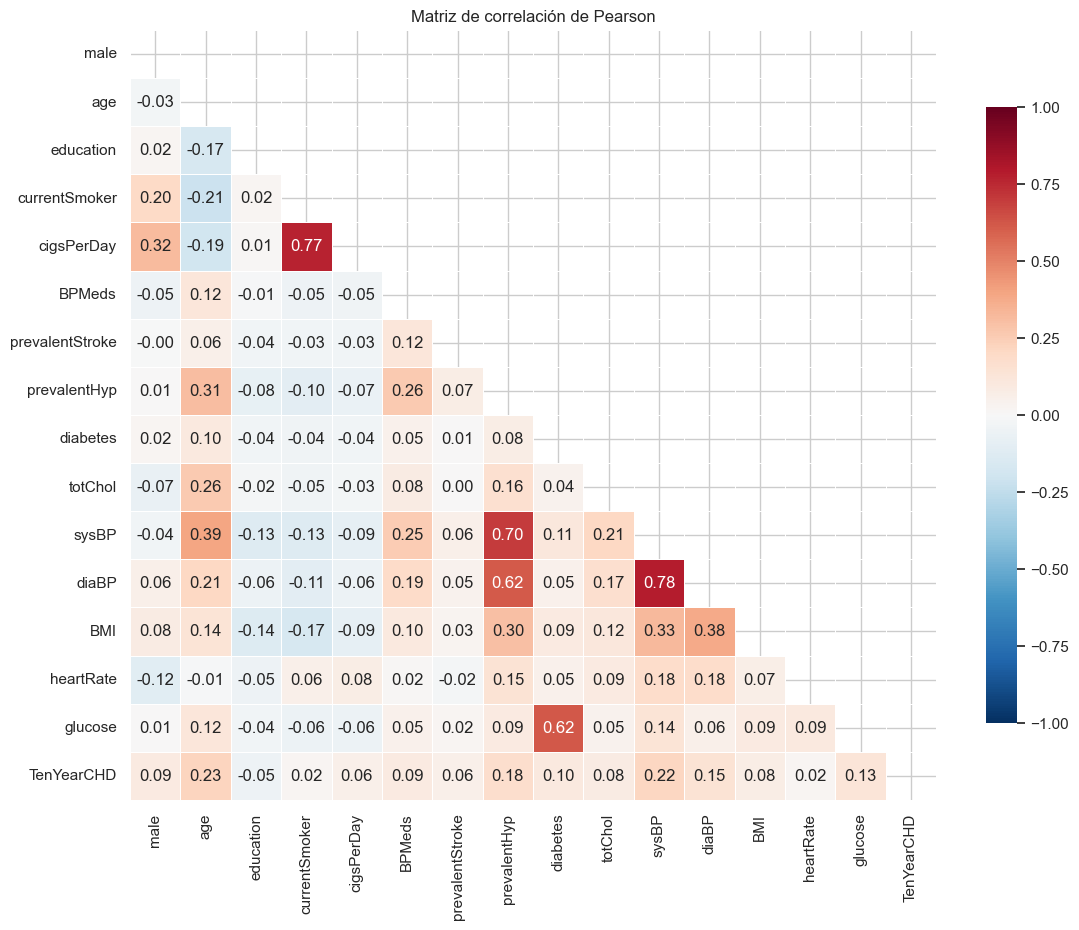

In [11]:
corr = dataset.corr()
mascara = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlación de Pearson')
guardar_figura('06_matriz_correlacion')
plt.show()

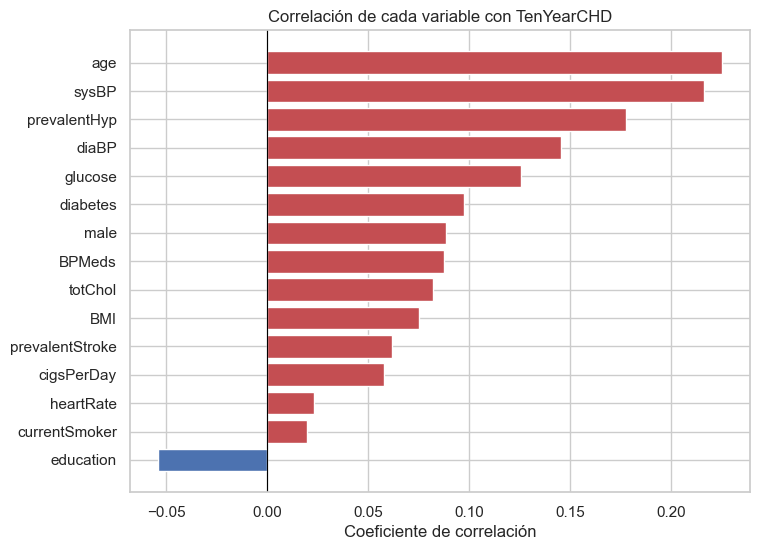

age                0.225
sysBP              0.216
prevalentHyp       0.178
diaBP              0.145
glucose            0.126
diabetes           0.097
male               0.088
BPMeds             0.087
totChol            0.082
BMI                0.075
prevalentStroke    0.062
cigsPerDay         0.058
heartRate          0.023
currentSmoker      0.019
education         -0.054
Name: TenYearCHD, dtype: float64

In [12]:
corr_objetivo = corr['TenYearCHD'].drop('TenYearCHD').sort_values()
plt.figure(figsize=(8, 6))
colores = [COLOR_CHD if v > 0 else COLOR_SANO for v in corr_objetivo]
plt.barh(corr_objetivo.index, corr_objetivo.values, color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlación de cada variable con TenYearCHD'); plt.xlabel('Coeficiente de correlación')
guardar_figura('07_correlacion_objetivo')
plt.show()
corr_objetivo.sort_values(ascending=False)


**Interpretación:**
- **Relación con la variable objetivo:** todas las correlaciones con `TenYearCHD` son **débiles**. Las más altas son edad (0.23), presión sistólica (0.22), hipertensión (0.18), presión diastólica (0.15) y glucosa (0.13). Ninguna variable por sí sola predice la enfermedad; se necesita un modelo que **combine** varios factores.
- **Relaciones fuertes entre predictores** (posible redundancia):
  - `sysBP` y `diaBP`: **0.78**, ambas miden presión arterial.
  - `currentSmoker` y `cigsPerDay`: **0.77**, un no fumador siempre tiene 0 cigarrillos.
  - `prevalentHyp` y `sysBP`: **0.70**, la hipertensión se diagnostica con la presión.
  - `diabetes` y `glucose`: **0.62**.

  Estas parejas aportan información parecida; se evaluará su efecto con el VIF en la sección 14.
- `education` tiene una correlación ligeramente negativa con el riesgo (−0.05): a mayor nivel educativo, el riesgo es levemente menor.


### 5.6 Revisión de valores atípicos
Se comparan los valores mínimos y máximos de las variables clínicas contra rangos fisiológicamente posibles, para distinguir **errores de captura** de **valores extremos reales**.

In [13]:
rangos_posibles = {'totChol': (70, 800), 'sysBP': (70, 300), 'diaBP': (40, 160), 'BMI': (12, 70),
                   'heartRate': (30, 200), 'glucose': (30, 500), 'cigsPerDay': (0, 100), 'age': (18, 100)}
revision = pd.DataFrame({
    'mínimo observado': dataset[list(rangos_posibles)].min(),
    'máximo observado': dataset[list(rangos_posibles)].max(),
    'rango posible': [f'{a} – {b}' for a, b in rangos_posibles.values()],
})
revision['valores fuera de rango'] = [((dataset[c] < a) | (dataset[c] > b)).sum() for c, (a, b) in rangos_posibles.items()]
revision

,mínimo observado,máximo observado,rango posible,valores fuera de rango
totChol,107.000,696.000,70 – 800,0
sysBP,83.500,295.000,70 – 300,0
diaBP,48.000,142.500,40 – 160,0
BMI,15.540,56.800,12 – 70,0
heartRate,44.000,143.000,30 – 200,0
glucose,40.000,394.000,30 – 500,0
cigsPerDay,0.000,70.000,0 – 100,0
age,32.000,70.000,18 – 100,0



**Interpretación:** **ningún valor está fuera del rango fisiológicamente posible**, por lo que no hay evidencia de errores de captura. Los valores extremos corresponden a condiciones clínicas reales: colesterol de 696 mg/dL (hipercolesterolemia familiar), presión sistólica de 295 mmHg (crisis hipertensiva) o glucosa de 394 mg/dL (diabetes descontrolada).

**Decisión: se conservan.** Estos pacientes son precisamente los de mayor riesgo, así que eliminarlos le quitaría al modelo información valiosa. Para que no dominen el ajuste, se usan la **mediana** (robusta a extremos) para imputar, el **escalado** y la **regularización** del modelo.


### 5.7 Hallazgos principales del EDA


1. **Desbalance de clases:** solo el 15.2 % de los pacientes desarrolló CHD. La exactitud no sirve como métrica, y hay que tratar el desbalance.
2. **La edad es el factor más fuerte:** el riesgo pasa de 4 % (30–39 años) a 28 % (60–70 años).
3. **La presión arterial y la hipertensión** son los factores clínicos con mayor relación con el riesgo, y la hipertensión afecta a casi un tercio de la población.
4. **Los antecedentes médicos multiplican el riesgo:** derrame previo (×2.9), diabetes (×2.5) y tratamiento para la presión (×2.3).
5. **Los hombres** tienen 1.5 veces más riesgo que las mujeres.
6. **El efecto del tabaquismo queda oculto por la edad** cuando se analiza por separado; requiere un análisis multivariable.
7. **Hay variables redundantes** (presión sistólica/diastólica, fumador/cigarrillos, diabetes/glucosa), que deben considerarse al seleccionar variables.
8. **Los datos faltantes son pocos y los valores extremos son clínicamente válidos:** se imputa en lugar de eliminar y se conservan los extremos.


## 6. Variables independientes (X) y dependiente (y)

- **Variables independientes (X):** las 15 primeras columnas (predictores).
- **Variable dependiente (y):** la última columna, `TenYearCHD`.

A diferencia del ejemplo de clase, se conservan como `DataFrame` de pandas (en lugar de convertirlas a arreglos con `.values`) para no perder los **nombres de las columnas**, que son necesarios para interpretar los coeficientes del modelo.

In [14]:
X = dataset.iloc[:, :-1]
y = dataset.iloc[:, -1]

print('X:', X.shape, '| y:', y.shape)
X.head()

X: (4238, 15) | y: (4238,)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
0,1,39,4.000,0,0.000,0.000,0,0,0,195.000,106.000,70.000,26.970,80.000,77.000
1,0,46,2.000,0,0.000,0.000,0,0,0,250.000,121.000,81.000,28.730,95.000,76.000
2,1,48,1.000,1,20.000,0.000,0,0,0,245.000,127.500,80.000,25.340,75.000,70.000
3,0,61,3.000,1,30.000,0.000,0,1,0,225.000,150.000,95.000,28.580,65.000,103.000
4,0,46,3.000,1,23.000,0.000,0,0,0,285.000,130.000,84.000,23.100,85.000,85.000


## 7. División del conjunto de datos en entrenamiento y prueba

Se separa un **20 %** de los datos como conjunto de **prueba**, que se reserva y **no se utiliza hasta la evaluación final**.

Dos decisiones importantes:

1. **`stratify=y`**: como la clase positiva es minoritaria (~15 %), la estratificación garantiza que ambos conjuntos conserven la misma proporción de pacientes con y sin CHD.
2. **La división se hace *antes* de imputar y escalar.** En el ejemplo de clase la imputación se realiza sobre todo el conjunto; aquí se invierte el orden para evitar la **fuga de datos** (*data leakage*): si la mediana o la media se calculan con todos los registros, el modelo "ve" información del conjunto de prueba y la evaluación resulta optimista. Por eso, todos los transformadores se ajustan (`fit`) **solo con el entrenamiento** y después se aplican (`transform`) a la prueba.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print('Entrenamiento:', X_train.shape, f'| % con CHD: {y_train.mean()*100:.1f}%')
print('Prueba:       ', X_test.shape, f'| % con CHD: {y_test.mean()*100:.1f}%')

Entrenamiento: (3390, 15) | % con CHD: 15.2%
Prueba:        (848, 15) | % con CHD: 15.2%


## 8. Tratamiento de datos faltantes

En lugar de aplicar una sola estrategia a todas las columnas, se elige la más adecuada **según el tipo de variable y su significado**:

| Variable | Estrategia | Justificación |
|---|---|---|
| `cigsPerDay` | **0** si `currentSmoker = 0`; **mediana de los fumadores** si `currentSmoker = 1` | Un no fumador fuma 0 cigarrillos. Para los fumadores, la mediana general estaría sesgada por los ceros de los no fumadores. |
| `education`, `BPMeds` | **Moda** (`most_frequent`) | Son variables categóricas/binarias: la media no tiene sentido (p. ej. 0.03 medicamentos). |
| `totChol`, `BMI`, `heartRate`, `glucose` | **Mediana** (`median`) | Son continuas con distribución asimétrica y valores extremos; la mediana es más robusta que la media. |

Se utiliza `SimpleImputer` (como en clase), ajustado **solo con el conjunto de entrenamiento**.

In [16]:
from sklearn.impute import SimpleImputer

X_train = X_train.copy()
X_test = X_test.copy()

# 1) cigsPerDay: regla lógica para no fumadores
for datos in (X_train, X_test):
    datos.loc[(datos['currentSmoker'] == 0) & (datos['cigsPerDay'].isnull()), 'cigsPerDay'] = 0

# 2) cigsPerDay: mediana de los fumadores (calculada solo con entrenamiento)
imputer_cigs = SimpleImputer(missing_values=np.nan, strategy='median')
imputer_cigs.fit(X_train.loc[X_train['currentSmoker'] == 1, ['cigsPerDay']])
print('Mediana de cigarrillos/día en fumadores (train):', imputer_cigs.statistics_[0])
for datos in (X_train, X_test):
    datos[['cigsPerDay']] = imputer_cigs.transform(datos[['cigsPerDay']])

# 3) Variables categóricas / binarias: moda
cols_moda = ['education', 'BPMeds']
imputer_moda = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
imputer_moda.fit(X_train[cols_moda])
X_train[cols_moda] = imputer_moda.transform(X_train[cols_moda])
X_test[cols_moda] = imputer_moda.transform(X_test[cols_moda])

# 4) Variables continuas: mediana
cols_mediana = ['totChol', 'BMI', 'heartRate', 'glucose']
imputer_mediana = SimpleImputer(missing_values=np.nan, strategy='median')
imputer_mediana.fit(X_train[cols_mediana])
X_train[cols_mediana] = imputer_mediana.transform(X_train[cols_mediana])
X_test[cols_mediana] = imputer_mediana.transform(X_test[cols_mediana])

print('\nValores usados para imputar (aprendidos del entrenamiento):')
print(pd.Series(np.concatenate([imputer_moda.statistics_, imputer_mediana.statistics_]).astype(float),
                index=cols_moda + cols_mediana))

Mediana de cigarrillos/día en fumadores (train): 20.0

Valores usados para imputar (aprendidos del entrenamiento):
education     1.000
BPMeds        0.000
totChol     232.000
BMI          25.410
heartRate    75.000
glucose      78.000
dtype: float64


In [17]:
print('Datos faltantes restantes -> entrenamiento:', int(X_train.isnull().sum().sum()),
      '| prueba:', int(X_test.isnull().sum().sum()))

Datos faltantes restantes -> entrenamiento: 0 | prueba: 0


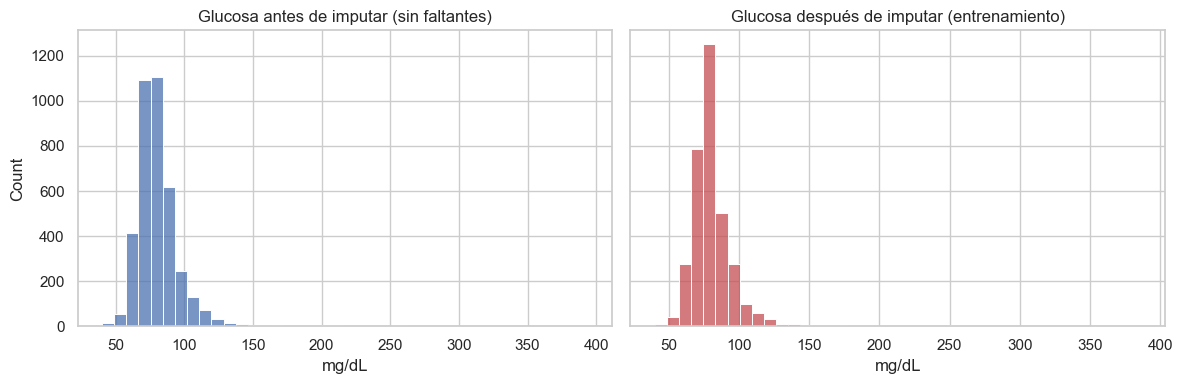

                    count   mean    std    min    25%    50%    75%     max
antes           3,850.000 81.967 23.960 40.000 71.000 78.000 87.000 394.000
después (train) 3,390.000 81.373 20.674 40.000 72.000 78.000 85.000 386.000


In [18]:
# Verificación: la imputación no debe deformar la distribución original de la glucosa
# (la variable con más faltantes, ~9 %)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.histplot(dataset['glucose'].dropna(), bins=40, ax=axes[0], color=COLOR_SANO)
axes[0].set_title('Glucosa antes de imputar (sin faltantes)')
sns.histplot(X_train['glucose'], bins=40, ax=axes[1], color=COLOR_CHD)
axes[1].set_title('Glucosa después de imputar (entrenamiento)')
for ax in axes: ax.set_xlabel('mg/dL')
plt.tight_layout()
guardar_figura('08_glucosa_antes_despues')
plt.show()
print(pd.DataFrame({'antes': dataset['glucose'].describe(), 'después (train)': X_train['glucose'].describe()}).T)


**Interpretación:**
- **Valores imputados** (aprendidos solo del entrenamiento): 20 cigarrillos/día para los fumadores, nivel educativo 1, sin medicamento para la presión (0), colesterol 232 mg/dL, IMC 25.41, frecuencia cardiaca 75 lpm y glucosa 78 mg/dL. Todos son valores clínicamente razonables.
- **La distribución de la glucosa se conserva:** la mediana se mantiene en 78 y la media apenas cambia (81.97 → 81.37). La desviación estándar baja de 23.96 a 20.67, un efecto esperado porque el 9 % de los valores se reemplaza por un mismo número; se reconoce como limitación en la sección 19.
- **Ya no quedan datos faltantes** en entrenamiento ni en prueba.


## 9. Codificación de datos categóricos

El conjunto de datos **no contiene variables de texto**: todas son numéricas. Sin embargo, hay que distinguir:

- **Variables binarias** (`male`, `currentSmoker`, `BPMeds`, `prevalentStroke`, `prevalentHyp`, `diabetes`): ya están codificadas como 0/1, así que **no requieren transformación** (equivalen al resultado de un `LabelEncoder`).
- **`education`**: es **categórica ordinal** codificada como 1, 2, 3, 4. Si se deja como número, el modelo supondría que la distancia entre cada nivel es la misma y que su efecto es lineal. Por eso se transforma con **One-Hot Encoding** mediante `ColumnTransformer`, igual que en el ejemplo de clase.

Se usa `drop='first'` para eliminar una de las columnas ficticias y evitar la **trampa de las variables ficticias** (*dummy variable trap*): con las 4 columnas, cualquiera de ellas se puede deducir de las otras tres (multicolinealidad perfecta). El nivel eliminado (`education = 1`) queda como **categoría de referencia**.

In [19]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

ct = ColumnTransformer(
    [('one_hot_encoder', OneHotEncoder(categories='auto', drop='first', handle_unknown='ignore', sparse_output=False), ['education'])],
    remainder='passthrough',
    verbose_feature_names_out=False
)
ct.set_output(transform='pandas')

X_train_cod = ct.fit_transform(X_train)
X_test_cod = ct.transform(X_test)

print('Columnas antes:', X_train.shape[1], '| columnas después:', X_train_cod.shape[1])
X_train_cod.head()

Columnas antes: 15 | columnas después: 17


,education_2.0,education_3.0,education_4.0,male,age,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
3013,0.000,0.000,1.000,1,42,0,0.000,0.000,0,0,0,191.000,118.000,80.000,24.980,62.000,63.000
4043,0.000,0.000,0.000,1,56,1,40.000,0.000,0,0,0,296.000,111.500,74.000,23.380,80.000,71.000
2420,0.000,0.000,0.000,0,53,0,0.000,0.000,0,1,0,180.000,184.500,110.500,27.490,62.000,74.000
2400,1.000,0.000,0.000,0,35,0,0.000,0.000,0,0,0,135.000,105.000,69.000,22.880,70.000,76.000
1364,1.000,0.000,0.000,0,41,1,20.000,0.000,0,0,0,235.000,144.000,88.000,24.160,95.000,82.000


## 10. Escalado de datos

Las variables tienen escalas muy distintas (edad ≈ 30–70, colesterol ≈ 100–700, binarias 0–1). Se aplica **`StandardScaler`** (estandarización: media 0 y desviación estándar 1) por tres razones:

1. El algoritmo de optimización de la Regresión Logística converge mejor con variables en escalas similares.
2. La **regularización** (penalización de coeficientes) trata a todas las variables por igual solo si están en la misma escala.
3. Los coeficientes resultantes son **comparables entre sí**: indican el efecto de aumentar una desviación estándar en cada variable.

Igual que en el ejemplo de clase, **solo se escalan las variables numéricas continuas**; las binarias y las columnas One-Hot se dejan en 0/1 porque ya están en una escala acotada y así conservan su interpretación ("tiene / no tiene el factor").

Para que el mismo preprocesamiento se aplique de forma idéntica en validación cruzada, prueba y en el dashboard, la codificación y el escalado se integran en un único `ColumnTransformer` llamado `preprocesador`.

In [20]:
from sklearn.preprocessing import StandardScaler

def crear_preprocesador(columnas):
    # One-Hot para education + StandardScaler para continuas; las binarias pasan sin cambios
    continuas = [c for c in ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose'] if c in columnas]
    transformadores = []
    if 'education' in columnas:
        transformadores.append(('one_hot_encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['education']))
    transformadores.append(('escalado', StandardScaler(), continuas))
    prep = ColumnTransformer(transformadores, remainder='passthrough', verbose_feature_names_out=False)
    return prep.set_output(transform='pandas')

preprocesador = crear_preprocesador(list(X_train.columns))
X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep = preprocesador.transform(X_test)

print('Media y desviación estándar de las continuas en entrenamiento (deben ser ~0 y ~1):')
X_train_prep[['age', 'totChol', 'sysBP', 'glucose']].agg(['mean', 'std'])

Media y desviación estándar de las continuas en entrenamiento (deben ser ~0 y ~1):


,age,totChol,sysBP,glucose
mean,0.000,0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000


In [21]:
X_train_prep.head()

,education_2.0,education_3.0,education_4.0,age,cigsPerDay,totChol,sysBP,diaBP,BMI,heartRate,glucose,male,currentSmoker,BPMeds,prevalentStroke,prevalentHyp,diabetes
3013,0.000,0.000,1.000,-0.875,-0.760,-1.031,-0.641,-0.237,-0.200,-1.157,-0.889,1,0,0.000,0,0,0
4043,0.000,0.000,0.000,0.767,2.566,1.392,-0.938,-0.741,-0.593,0.346,-0.502,1,1,0.000,0,0,0
2420,0.000,0.000,0.000,0.415,-0.760,-1.285,2.393,2.324,0.418,-1.157,-0.357,0,0,0.000,0,1,0
2400,1.000,0.000,0.000,-1.696,-0.760,-2.324,-1.234,-1.161,-0.716,-0.489,-0.260,0,0,0.000,0,0,0
1364,1.000,0.000,0.000,-0.992,0.903,-0.016,0.545,0.435,-0.401,1.599,0.030,0,1,0.000,0,0,0


## 11. Fundamentos de la Regresión Logística

La **Regresión Logística** es un modelo de clasificación que estima la **probabilidad** de que una observación pertenezca a la clase positiva (en este caso, desarrollar CHD).

**1. Combinación lineal.** Igual que en la regresión lineal, se calcula una suma ponderada de las variables:

$$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

**2. Función sigmoide.** Para convertir $z$ (que puede ir de $-\infty$ a $+\infty$) en una probabilidad entre 0 y 1, se aplica la función logística o sigmoide:

$$P(y = 1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}}$$

**3. Clasificación con umbral.** Si la probabilidad supera un **umbral** (por defecto 0.5), el paciente se clasifica como positivo. Este umbral **se puede ajustar** según el costo de cada tipo de error.

**4. Odds y odds ratio (interpretación).** Los *odds* (momios) son el cociente entre la probabilidad de que ocurra el evento y la de que no ocurra: $\text{odds} = \frac{p}{1-p}$. El modelo es lineal en el logaritmo de los odds:

$$\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$$

Por eso, $e^{\beta_i}$ es el **odds ratio** de la variable $x_i$: cuántas veces se multiplican los odds de desarrollar CHD cuando $x_i$ aumenta una unidad, manteniendo constantes las demás variables. Un odds ratio **> 1** indica un factor de **riesgo**; **< 1**, un factor **protector**.

**5. Entrenamiento.** Los coeficientes $\beta$ se obtienen minimizando la **pérdida logarítmica** (*log-loss* o entropía cruzada). En `scikit-learn` se añade además una **regularización** controlada por el hiperparámetro `C` (inverso de la fuerza de regularización): valores pequeños de `C` penalizan más los coeficientes grandes y ayudan a evitar el sobreajuste. Con `penalty='l1'` (Lasso) algunos coeficientes pueden volverse exactamente 0 (selección de variables); con `penalty='l2'` (Ridge) solo se reducen.

**¿Por qué Regresión Logística para este problema?**
- Entrega una **probabilidad de riesgo**, no solo un "sí/no", lo que es muy útil en medicina.
- Es **interpretable**: cada coeficiente indica cómo influye un factor en el riesgo.
- Es el modelo de referencia en estudios clínicos; de hecho, las escalas de riesgo cardiovascular derivadas del propio estudio Framingham se basan en modelos de este tipo.

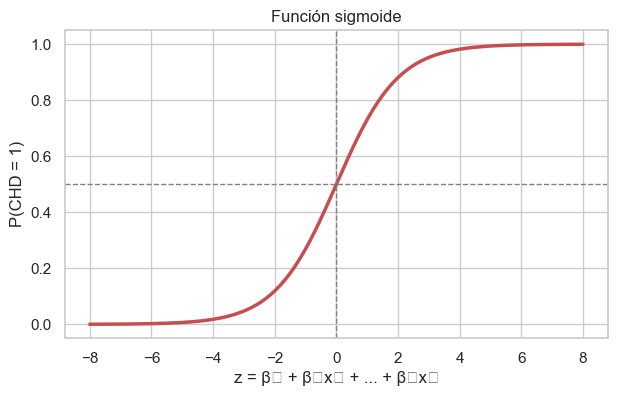

In [22]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(7, 4))
plt.plot(z, 1 / (1 + np.exp(-z)), color=COLOR_CHD, linewidth=2.5)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1); plt.axvline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Función sigmoide'); plt.xlabel('z = β₀ + β₁x₁ + ... + βₙxₙ'); plt.ylabel('P(CHD = 1)')
guardar_figura('09_funcion_sigmoide')
plt.show()

## 12. Modelo base

Primero se entrena una Regresión Logística **con los parámetros por defecto**, sin tratar el desbalance y con el umbral estándar de 0.5. Este modelo sirve como **punto de comparación** para medir el efecto de cada mejora posterior.

### Métricas de evaluación utilizadas

| Métrica | Pregunta que responde | Fórmula |
|---|---|---|
| **Exactitud** (*accuracy*) | ¿Qué porcentaje de pacientes se clasificó bien? | (VP + VN) / Total |
| **Sensibilidad** (*recall*) | De los pacientes que **sí** desarrollaron CHD, ¿cuántos detectó el modelo? | VP / (VP + FN) |
| **Especificidad** | De los pacientes que **no** desarrollaron CHD, ¿cuántos identificó como sanos? | VN / (VN + FP) |
| **Precisión** (*precision*) | De los pacientes que el modelo marcó como riesgo, ¿cuántos realmente desarrollaron CHD? | VP / (VP + FP) |
| **F1** | Balance entre precisión y sensibilidad | 2·P·S / (P + S) |
| **ROC-AUC** | ¿Qué tan bien ordena el modelo a los pacientes de mayor a menor riesgo, sin depender del umbral? | Área bajo la curva ROC (0.5 = azar, 1 = perfecto) |

VP = verdaderos positivos, VN = verdaderos negativos, FP = falsos positivos, FN = falsos negativos.

En este problema, **un falso negativo (no detectar a un paciente en riesgo) es mucho más grave que un falso positivo** (enviar a estudios adicionales a una persona sana). Por eso, la **sensibilidad** y el **ROC-AUC** son más importantes que la exactitud.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay, classification_report)

def calcular_metricas(y_real, y_pred, y_prob):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred).ravel()
    return {'Exactitud': accuracy_score(y_real, y_pred),
            'Sensibilidad (recall)': recall_score(y_real, y_pred),
            'Especificidad': vn / (vn + fp),
            'Precisión': precision_score(y_real, y_pred, zero_division=0),
            'F1': f1_score(y_real, y_pred),
            'ROC-AUC': roc_auc_score(y_real, y_prob)}

modelo_base = LogisticRegression(random_state=RANDOM_STATE)
modelo_base.fit(X_train_prep, y_train)

prob_base = modelo_base.predict_proba(X_test_prep)[:, 1]
pred_base = modelo_base.predict(X_test_prep)

metricas_base = calcular_metricas(y_test, pred_base, prob_base)
pd.Series(metricas_base, name='Modelo base').to_frame()

,Modelo base
Exactitud,0.853
Sensibilidad (recall),0.078
Especificidad,0.992
Precisión,0.625
F1,0.138
ROC-AUC,0.713


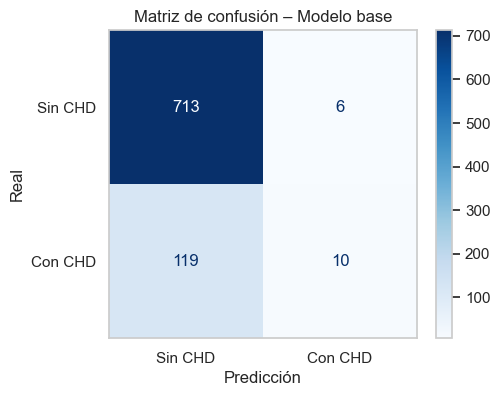

In [24]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_base, display_labels=['Sin CHD', 'Con CHD'], cmap='Blues', ax=ax)
ax.set_title('Matriz de confusión – Modelo base'); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.grid(False)
plt.show()


**Interpretación:** la exactitud de **85.3 %** parece buena, pero es engañosa: es prácticamente igual al 84.8 % que se obtendría diciendo siempre "no desarrollará CHD". La **sensibilidad es de apenas 7.8 %**: de los 129 pacientes del conjunto de prueba que sí desarrollaron CHD, el modelo **solo detecta 10** y deja escapar 119.

Sin embargo, el **ROC-AUC de 0.713** indica que el modelo **sí sabe ordenar** a los pacientes por riesgo (asigna probabilidades más altas a quienes enferman). El problema no es la capacidad de discriminar, sino que, con una clase tan minoritaria, casi ninguna probabilidad supera el umbral de 0.5. Las secciones siguientes atacan este problema.


## 13. Tratamiento del desbalance de clases

Se comparan tres estrategias usando **validación cruzada estratificada de 5 particiones** sobre el conjunto de entrenamiento (el de prueba sigue sin tocarse):

1. **Sin balanceo** (modelo base).
2. **`class_weight='balanced'`**: la Regresión Logística asigna más peso a los errores en la clase minoritaria, de forma inversamente proporcional a su frecuencia. No crea datos nuevos.
3. **SMOTE** (*Synthetic Minority Over-sampling Technique*): genera pacientes **sintéticos** de la clase minoritaria interpolando entre vecinos cercanos, hasta igualar ambas clases.

Para que la comparación sea justa, el preprocesamiento y SMOTE se colocan dentro de un `Pipeline` de `imbalanced-learn`. Así, en cada partición de la validación cruzada se ajustan **solo con los datos de entrenamiento de esa partición**, y SMOTE **nunca** genera datos sintéticos en la partición de validación.

> **Validación cruzada:** el entrenamiento se divide en 5 partes; el modelo se entrena 5 veces con 4 partes y se evalúa con la parte restante. El promedio de las 5 evaluaciones es una estimación más confiable que una sola división.

Además de las métricas de clasificación (calculadas con el umbral de 0.5), se incluye el **Brier score**: el error cuadrático medio entre la probabilidad estimada y el resultado real (0 = perfecto). Mide la **calibración**, es decir, si una probabilidad de 20 % corresponde realmente a que ~20 de cada 100 pacientes enferman. Esto es importante porque el dashboard mostrará la probabilidad de riesgo a cada paciente.

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas_cv = {'roc_auc': 'roc_auc', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'accuracy': 'accuracy',
               'brier': 'neg_brier_score'}

estrategias = {
    'Sin balanceo': Pipeline([('prep', crear_preprocesador(list(X_train.columns))),
                              ('modelo', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))]),
    "class_weight='balanced'": Pipeline([('prep', crear_preprocesador(list(X_train.columns))),
                                         ('modelo', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, max_iter=1000))]),
    'SMOTE': Pipeline([('prep', crear_preprocesador(list(X_train.columns))),
                       ('smote', SMOTE(random_state=RANDOM_STATE)),
                       ('modelo', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))]),
}

resultados = {}
for nombre, pipe in estrategias.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas_cv)
    resultados[nombre] = {m: abs(r[f'test_{m}'].mean()) for m in metricas_cv}

tabla_balanceo = pd.DataFrame(resultados).T
tabla_balanceo.columns = ['ROC-AUC', 'Sensibilidad', 'Precisión', 'F1', 'Exactitud', 'Brier score']
tabla_balanceo

,ROC-AUC,Sensibilidad,Precisión,F1,Exactitud,Brier score
Sin balanceo,0.727,0.091,0.672,0.160,0.855,0.116
class_weight='balanced',0.726,0.674,0.275,0.390,0.681,0.208
SMOTE,0.706,0.635,0.258,0.366,0.667,0.213


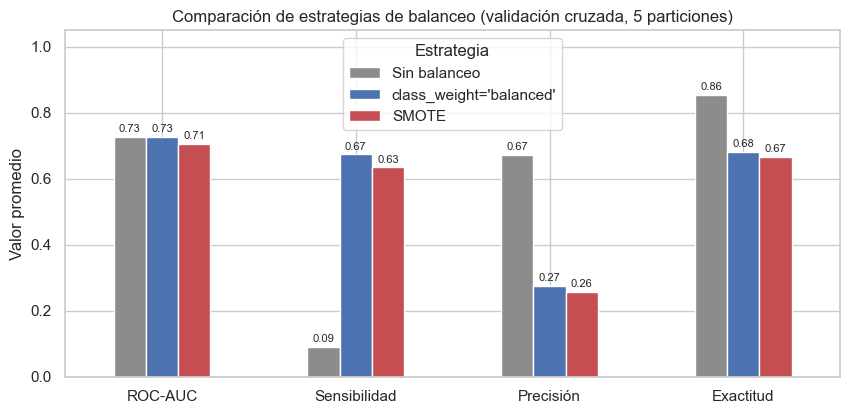

In [26]:
ax = tabla_balanceo[['ROC-AUC', 'Sensibilidad', 'Precisión', 'Exactitud']].T.plot(kind='bar', figsize=(10, 4.5), rot=0,
                                                                                    color=['#8C8C8C', COLOR_SANO, COLOR_CHD])
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
plt.title('Comparación de estrategias de balanceo (validación cruzada, 5 particiones)')
plt.ylabel('Valor promedio'); plt.ylim(0, 1.05); plt.legend(title='Estrategia')
guardar_figura('10_comparacion_balanceo')
plt.show()


**Interpretación:**
- `class_weight='balanced'` y SMOTE **elevan la sensibilidad** (con umbral 0.5) de 9 % a 67 % y 64 %, respectivamente, a cambio de bajar la precisión y la exactitud.
- Sin embargo, **ninguna mejora el ROC-AUC**: sin balanceo se obtiene 0.727, con `class_weight` 0.726 y con SMOTE 0.706 (incluso peor, porque los pacientes sintéticos añaden ruido). Es decir, **no hacen que el modelo distinga mejor** a los pacientes en riesgo; solo **desplazan las probabilidades hacia arriba**, de modo que más pacientes superan el 0.5.
- Ese desplazamiento tiene un costo: el **Brier score casi se duplica** (0.116 → 0.208). Las probabilidades dejan de ser realistas: un paciente con un riesgo real de 15 % aparecería con uno cercano al 50 %.

**Decisión:** no se modifican los datos ni los pesos. El desbalance se trata **ajustando el umbral de decisión** (sección 15), que logra la misma ganancia en sensibilidad y además:
1. conserva **probabilidades calibradas**, indispensables para mostrar el riesgo real en el dashboard;
2. no crea pacientes sintéticos;
3. permite elegir de forma explícita el equilibrio entre sensibilidad y precisión.


## 14. Selección de variables y optimización del modelo

### 14.1 Multicolinealidad (VIF)

Cuando dos o más variables están muy relacionadas entre sí (por ejemplo, presión sistólica y diastólica), los coeficientes de la Regresión Logística se vuelven inestables y difíciles de interpretar. El **Factor de Inflación de la Varianza (VIF)** mide cuánto se "infla" la varianza de un coeficiente por esa relación:

- VIF ≈ 1: sin multicolinealidad
- VIF entre 5 y 10: multicolinealidad moderada, conviene revisarla
- VIF > 10: multicolinealidad alta

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_vif = sm.add_constant(X_train.astype(float))
vif = pd.DataFrame({'variable': X_vif.columns,
                    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
vif = vif[vif['variable'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
vif

,variable,VIF
0,sysBP,3.686
1,diaBP,3.001
2,cigsPerDay,2.648
3,currentSmoker,2.489
4,prevalentHyp,2.022
5,glucose,1.563
6,diabetes,1.546
7,age,1.360
8,BMI,1.236
9,male,1.211



**Interpretación:** **todas las variables tienen un VIF menor a 5**, por lo que no hay multicolinealidad grave. Los valores más altos corresponden a las parejas redundantes detectadas en el EDA: `sysBP` (3.69) y `diaBP` (3.00), y `cigsPerDay` (2.65) y `currentSmoker` (2.49). No es necesario eliminar variables solo por VIF, pero las redundantes son candidatas a salir en la selección.


### 14.2 Significancia estadística de las variables

Se ajusta una Regresión Logística con `statsmodels`, que además de los coeficientes entrega su **valor p**. Un valor p < 0.05 indica que la variable tiene una asociación estadísticamente significativa con el riesgo de CHD, una vez considerado el efecto de las demás variables.

In [28]:
X_sm = sm.add_constant(X_train_cod.astype(float))
logit_completo = sm.Logit(y_train.values, X_sm).fit(disp=0)

significancia = pd.DataFrame({'coeficiente': logit_completo.params, 'valor p': logit_completo.pvalues}).drop('const')
significancia['significativa (p < 0.05)'] = np.where(significancia['valor p'] < 0.05, 'Sí', 'No')
significancia.sort_values('valor p')

,coeficiente,valor p,significativa (p < 0.05)
age,0.065,0.000,Sí
male,0.537,0.000,Sí
sysBP,0.013,0.001,Sí
glucose,0.007,0.010,Sí
cigsPerDay,0.016,0.013,Sí
prevalentStroke,1.229,0.015,Sí
prevalentHyp,0.209,0.145,No
totChol,0.002,0.191,No
education_2.0,-0.146,0.257,No
BPMeds,0.264,0.289,No



**Interpretación:** **6 variables son estadísticamente significativas**: edad, sexo masculino, presión sistólica, glucosa, cigarrillos por día y derrame previo.

Varias variables que en el EDA sí mostraban relación con el riesgo **dejan de ser significativas** al analizarse junto con las demás, porque su información ya la aporta otra variable:
- `diaBP` → la cubre `sysBP`;
- `currentSmoker` → la cubre `cigsPerDay`;
- `diabetes` → la cubre `glucose`;
- `BPMeds` → la cubren `sysBP` y la hipertensión.

`BMI`, `heartRate` y `education` no aportan información adicional.

**Variables seleccionadas (8):** las 6 significativas, más **hipertensión** (`prevalentHyp`, p = 0.145) y **colesterol total** (`totChol`, p = 0.191). Estas dos se conservan por criterio clínico: son factores de riesgo cardiovascular ampliamente reconocidos (forman parte de las escalas de riesgo derivadas del propio estudio Framingham) y son **modificables**, lo que las hace relevantes para las recomendaciones y el dashboard.


### 14.3 Comparación: todas las variables vs. variables seleccionadas

Se compara, con validación cruzada, el modelo con las 15 variables contra uno que solo usa las variables significativas. Si el desempeño es prácticamente igual, se prefiere el **modelo más simple** (principio de parsimonia): es más fácil de interpretar, de explicar y de usar en el dashboard (el usuario captura menos datos).

In [29]:
variables_todas = list(X_train.columns)
variables_seleccionadas = ['male', 'age', 'cigsPerDay', 'sysBP', 'glucose', 'prevalentStroke', 'prevalentHyp', 'totChol']

def pipeline_logistico(columnas, balanceo, **params):
    # Construye el pipeline: preprocesamiento -> (SMOTE opcional) -> Regresión Logística
    pasos = [('prep', crear_preprocesador(columnas))]
    if balanceo == 'SMOTE':
        pasos.append(('smote', SMOTE(random_state=RANDOM_STATE)))
    pesos = 'balanced' if balanceo == 'class_weight' else None
    pasos.append(('modelo', LogisticRegression(class_weight=pesos, random_state=RANDOM_STATE, max_iter=1000, **params)))
    return Pipeline(pasos)

ESTRATEGIA = 'ninguno'   # estrategia elegida en la sección 13

comparacion_vars = {}
for nombre, cols in {'Todas (15)': variables_todas, f'Seleccionadas ({len(variables_seleccionadas)})': variables_seleccionadas}.items():
    r = cross_validate(pipeline_logistico(cols, ESTRATEGIA), X_train[cols], y_train, cv=cv,
                       scoring={'roc_auc': 'roc_auc', 'brier': 'neg_brier_score'})
    comparacion_vars[nombre] = {'ROC-AUC promedio': r['test_roc_auc'].mean(), 'ROC-AUC desv. estándar': r['test_roc_auc'].std(),
                                'Brier score': -r['test_brier'].mean()}

tabla_vars = pd.DataFrame(comparacion_vars).T
print('Variables seleccionadas:', variables_seleccionadas)
tabla_vars

Variables seleccionadas: ['male', 'age', 'cigsPerDay', 'sysBP', 'glucose', 'prevalentStroke', 'prevalentHyp', 'totChol']


,ROC-AUC promedio,ROC-AUC desv. estándar,Brier score
Todas (15),0.727,0.018,0.116
Seleccionadas (8),0.730,0.019,0.115



**Interpretación:** el modelo con **8 variables** obtiene un ROC-AUC de **0.730**, ligeramente superior al de las 15 variables (**0.727**), con la misma calibración (Brier 0.115 vs. 0.116). Eliminar 7 variables **no pierde información**: incluso mejora un poco, porque se quita ruido.

**Decisión:** se usa el modelo con **8 variables**. Es más simple, más fácil de interpretar y requiere menos datos de entrada en el dashboard.

> En esta comparación solo se usan métricas que no dependen del umbral (ROC-AUC y Brier), porque el umbral se ajustará después.


### 14.4 Optimización de hiperparámetros (GridSearchCV)

Se buscan los mejores valores de:

- **`C`**: inverso de la fuerza de regularización (valores pequeños = modelo más simple).
- **`penalty`**: tipo de regularización, `l1` (Lasso) o `l2` (Ridge).

`GridSearchCV` prueba **todas las combinaciones** con validación cruzada de 5 particiones y elige la que obtiene el mayor **ROC-AUC**. Se usa ROC-AUC como criterio porque no depende del umbral: el umbral se ajusta por separado en la siguiente sección.

In [30]:
from sklearn.model_selection import GridSearchCV

VARIABLES_FINALES = variables_seleccionadas

parametros = {
    'modelo__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'modelo__penalty': ['l1', 'l2'],
    'modelo__solver': ['liblinear'],
}

busqueda = GridSearchCV(pipeline_logistico(VARIABLES_FINALES, ESTRATEGIA), parametros, cv=cv,
                        scoring='roc_auc')
busqueda.fit(X_train[VARIABLES_FINALES], y_train)

print('Mejores hiperparámetros:', busqueda.best_params_)
print(f'ROC-AUC promedio en validación cruzada: {busqueda.best_score_:.4f}')

resultados_grid = pd.DataFrame(busqueda.cv_results_)[['param_modelo__C', 'param_modelo__penalty', 'mean_test_score', 'std_test_score']]
resultados_grid.columns = ['C', 'penalty', 'ROC-AUC promedio', 'desv. estándar']
resultados_grid.sort_values('ROC-AUC promedio', ascending=False).head(8)

Mejores hiperparámetros: {'modelo__C': 1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
ROC-AUC promedio en validación cruzada: 0.7305


,C,penalty,ROC-AUC promedio,desv. estándar
7,1.000,l2,0.730,0.019
6,1.000,l1,0.730,0.019
9,10.000,l2,0.730,0.019
11,100.000,l2,0.730,0.019
8,10.000,l1,0.730,0.019
10,100.000,l1,0.730,0.019
5,0.100,l2,0.729,0.020
4,0.100,l1,0.728,0.020


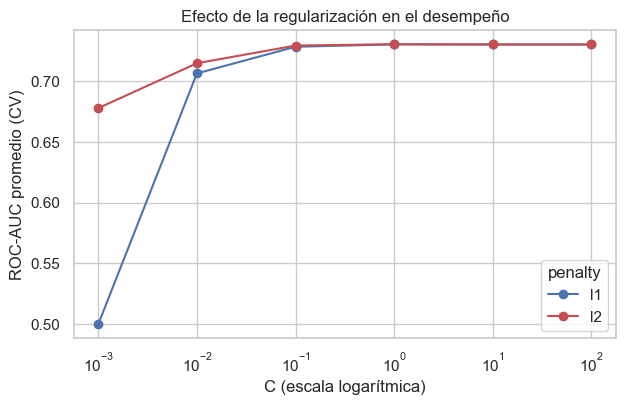

In [31]:
tabla_grid = resultados_grid.pivot(index='C', columns='penalty', values='ROC-AUC promedio')
plt.figure(figsize=(7, 4))
for pen, color in zip(tabla_grid.columns, [COLOR_SANO, COLOR_CHD]):
    plt.plot(tabla_grid.index, tabla_grid[pen], marker='o', label=pen, color=color)
plt.xscale('log'); plt.xlabel('C (escala logarítmica)'); plt.ylabel('ROC-AUC promedio (CV)')
plt.title('Efecto de la regularización en el desempeño'); plt.legend(title='penalty')
guardar_figura('11_gridsearch')
plt.show()

modelo_final = busqueda.best_estimator_


**Interpretación:** el ROC-AUC es prácticamente el mismo (**0.730**) para cualquier `C` entre 1 y 100, con `l1` o `l2`; solo con una regularización muy fuerte (`C` ≤ 0.01) el desempeño baja ligeramente. La mejor combinación es **`C = 1` con `penalty = 'l2'`**, que coincide con los valores por defecto.

Esto indica que, con 8 variables y 3,390 registros de entrenamiento, **el modelo no sufre sobreajuste**, así que no necesita una regularización adicional. La búsqueda confirma de forma objetiva que la configuración elegida es la adecuada.


## 15. Ajuste del umbral de decisión

Por defecto, un paciente se clasifica como "en riesgo" si su probabilidad es ≥ 0.5. Sin embargo, ese valor es arbitrario: **mover el umbral** cambia el equilibrio entre sensibilidad y precisión.

- Umbral **más bajo** → se detectan más pacientes en riesgo (↑ sensibilidad), pero aumentan las falsas alarmas (↓ precisión).
- Umbral **más alto** → menos falsas alarmas, pero se escapan más pacientes enfermos.

**Criterio elegido: maximizar la métrica F2.** La $F_\beta$ combina precisión y sensibilidad; con $\beta = 2$ la sensibilidad pesa **el doble** que la precisión, lo que refleja que en tamizaje médico es más costoso no detectar a un paciente en riesgo:

$$F_2 = \frac{(1 + 2^2) \cdot \text{Precisión} \cdot \text{Sensibilidad}}{2^2 \cdot \text{Precisión} + \text{Sensibilidad}}$$

El umbral se elige con las **predicciones de validación cruzada sobre el entrenamiento** (`cross_val_predict`), **no** con el conjunto de prueba, para que la evaluación final siga siendo imparcial.

In [32]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, fbeta_score

prob_cv = cross_val_predict(modelo_final, X_train[VARIABLES_FINALES], y_train, cv=cv, method='predict_proba')[:, 1]

umbrales = np.arange(0.05, 0.95, 0.01)
curva = pd.DataFrame({
    'umbral': umbrales,
    'Sensibilidad': [recall_score(y_train, prob_cv >= u) for u in umbrales],
    'Precisión': [precision_score(y_train, prob_cv >= u, zero_division=0) for u in umbrales],
    'F2': [fbeta_score(y_train, prob_cv >= u, beta=2) for u in umbrales],
    'Especificidad': [((prob_cv < u) & (y_train == 0)).sum() / (y_train == 0).sum() for u in umbrales],
})
UMBRAL = round(float(curva.loc[curva['F2'].idxmax(), 'umbral']), 2)
print(f'Umbral óptimo (máximo F2): {UMBRAL}')
curva[curva['umbral'].round(2).isin([0.3, 0.4, UMBRAL, 0.5, 0.6, 0.7])].round(3)

Umbral óptimo (máximo F2): 0.12


,umbral,Sensibilidad,Precisión,F2,Especificidad
7,0.120,0.767,0.236,0.529,0.555
25,0.300,0.283,0.372,0.298,0.914
35,0.400,0.148,0.510,0.172,0.975
45,0.500,0.082,0.656,0.099,0.992
55,0.600,0.037,0.826,0.046,0.999
65,0.700,0.012,0.857,0.015,1.000


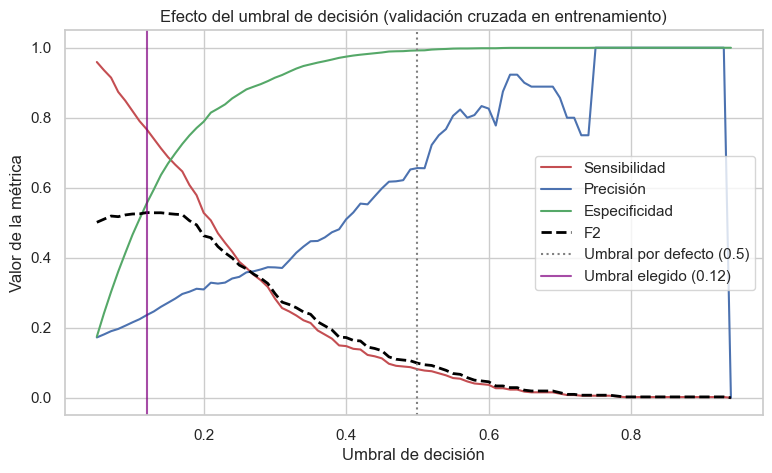

In [33]:
plt.figure(figsize=(9, 5))
for col, color in zip(['Sensibilidad', 'Precisión', 'Especificidad', 'F2'], [COLOR_CHD, COLOR_SANO, '#55A868', 'black']):
    plt.plot(curva['umbral'], curva[col], label=col, color=color, linewidth=2 if col == 'F2' else 1.5,
             linestyle='--' if col == 'F2' else '-')
plt.axvline(0.5, color='gray', linestyle=':', label='Umbral por defecto (0.5)')
plt.axvline(UMBRAL, color='purple', linestyle='-', alpha=0.7, label=f'Umbral elegido ({UMBRAL})')
plt.xlabel('Umbral de decisión'); plt.ylabel('Valor de la métrica')
plt.title('Efecto del umbral de decisión (validación cruzada en entrenamiento)')
plt.legend(loc='center right')
guardar_figura('12_ajuste_umbral')
plt.show()


**Interpretación:** el umbral que maximiza F2 es **0.12**. Con él, en validación cruzada, el modelo detecta al **76.7 %** de los pacientes que desarrollan CHD (contra 8.2 % con el umbral de 0.5), con una precisión de 23.6 % y una especificidad de 55.5 %.

**¿Por qué un umbral tan bajo?** Porque el riesgo promedio de la población es de 15 %. Una probabilidad de 12 % ya está cerca del promedio, y lo que se busca es identificar a quienes están **por encima de lo esperado** para canalizarlos a una evaluación más detallada. Este criterio es coherente con la práctica clínica, donde un riesgo cardiovascular a 10 años a partir de ~7.5–10 % suele considerarse intermedio o alto y justifica intervenciones preventivas.


## 16. Evaluación final en el conjunto de prueba

Por primera vez se utiliza el **conjunto de prueba** (20 % reservado desde la sección 7). Se compara el modelo base contra el modelo final con el umbral por defecto y con el umbral ajustado.

In [34]:
prob_final = modelo_final.predict_proba(X_test[VARIABLES_FINALES])[:, 1]
pred_final_05 = (prob_final >= 0.5).astype(int)
pred_final = (prob_final >= UMBRAL).astype(int)

tabla_final = pd.DataFrame({
    'Modelo base (umbral 0.5)': metricas_base,
    'Modelo final (umbral 0.5)': calcular_metricas(y_test, pred_final_05, prob_final),
    f'Modelo final (umbral {UMBRAL})': calcular_metricas(y_test, pred_final, prob_final),
})
tabla_final

,Modelo base (umbral 0.5),Modelo final (umbral 0.5),Modelo final (umbral 0.12)
Exactitud,0.853,0.851,0.552
Sensibilidad (recall),0.078,0.078,0.798
Especificidad,0.992,0.990,0.508
Precisión,0.625,0.588,0.225
F1,0.138,0.137,0.352
ROC-AUC,0.713,0.713,0.713


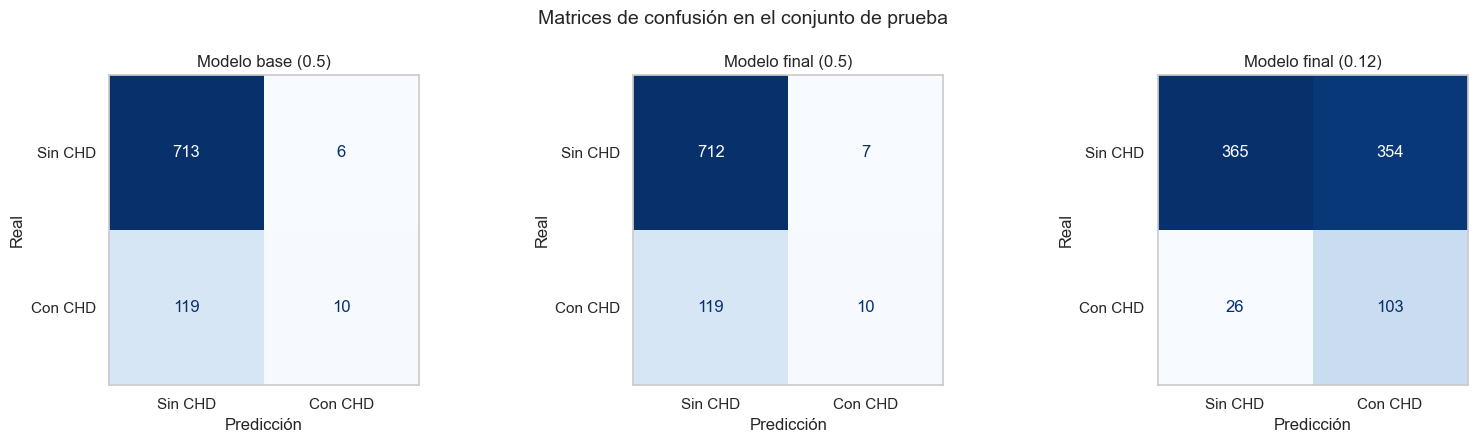

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (titulo, pred) in zip(axes, [('Modelo base (0.5)', pred_base),
                                     ('Modelo final (0.5)', pred_final_05),
                                     (f'Modelo final ({UMBRAL})', pred_final)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Sin CHD', 'Con CHD'],
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(titulo); ax.set_xlabel('Predicción'); ax.set_ylabel('Real'); ax.grid(False)
plt.suptitle('Matrices de confusión en el conjunto de prueba', fontsize=14)
plt.tight_layout()
guardar_figura('13_matrices_confusion')
plt.show()

In [36]:
print(classification_report(y_test, pred_final, target_names=['Sin CHD', 'Con CHD'], digits=3))

              precision    recall  f1-score   support

     Sin CHD      0.934     0.508     0.658       719
     Con CHD      0.225     0.798     0.352       129

    accuracy                          0.552       848
   macro avg      0.579     0.653     0.505       848
weighted avg      0.826     0.552     0.611       848



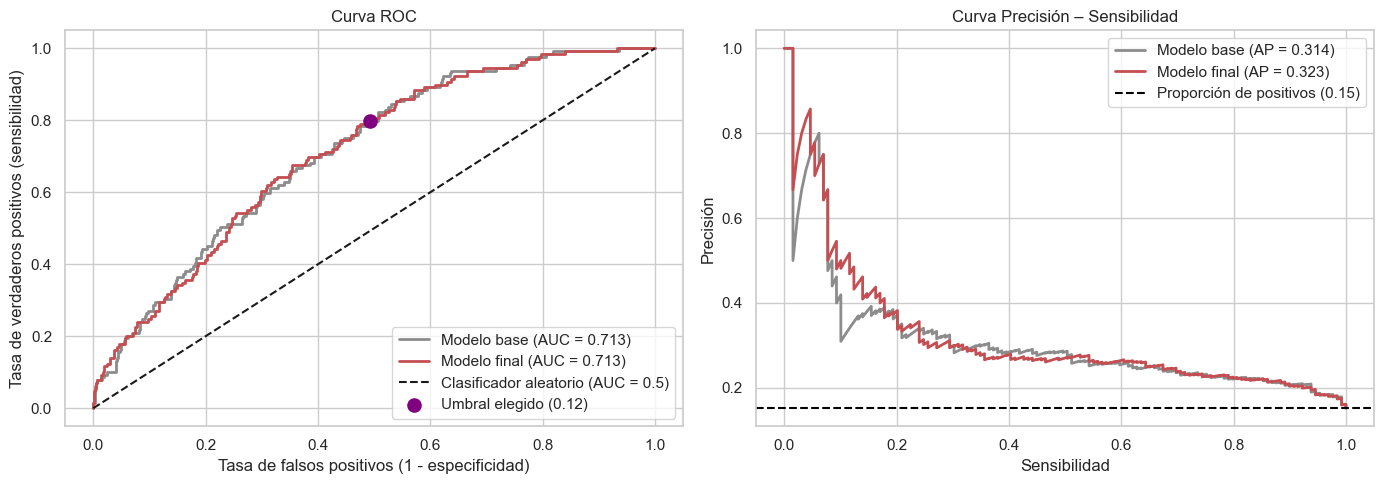

In [37]:
from sklearn.metrics import roc_curve, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for nombre, prob, color in [('Modelo base', prob_base, '#8C8C8C'), ('Modelo final', prob_final, COLOR_CHD)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=f'{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})')
    p, r, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(r, p, color=color, linewidth=2, label=f'{nombre} (AP = {average_precision_score(y_test, prob):.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', label='Clasificador aleatorio (AUC = 0.5)')
vn, fp, fn, vp = confusion_matrix(y_test, pred_final).ravel()
axes[0].scatter(fp / (fp + vn), vp / (vp + fn), s=90, color='purple', zorder=5, label=f'Umbral elegido ({UMBRAL})')
axes[0].set_title('Curva ROC'); axes[0].set_xlabel('Tasa de falsos positivos (1 - especificidad)')
axes[0].set_ylabel('Tasa de verdaderos positivos (sensibilidad)'); axes[0].legend(loc='lower right')

axes[1].axhline(y_test.mean(), color='black', linestyle='--', label=f'Proporción de positivos ({y_test.mean():.2f})')
axes[1].set_title('Curva Precisión – Sensibilidad'); axes[1].set_xlabel('Sensibilidad'); axes[1].set_ylabel('Precisión')
axes[1].legend(loc='upper right')
plt.tight_layout()
guardar_figura('14_curvas_roc_pr')
plt.show()

In [38]:
# Comparación entrenamiento (CV) vs prueba para descartar sobreajuste
print(f'ROC-AUC validación cruzada (entrenamiento): {busqueda.best_score_:.3f}')
print(f'ROC-AUC conjunto de prueba:                 {roc_auc_score(y_test, prob_final):.3f}')

ROC-AUC validación cruzada (entrenamiento): 0.730
ROC-AUC conjunto de prueba:                 0.713


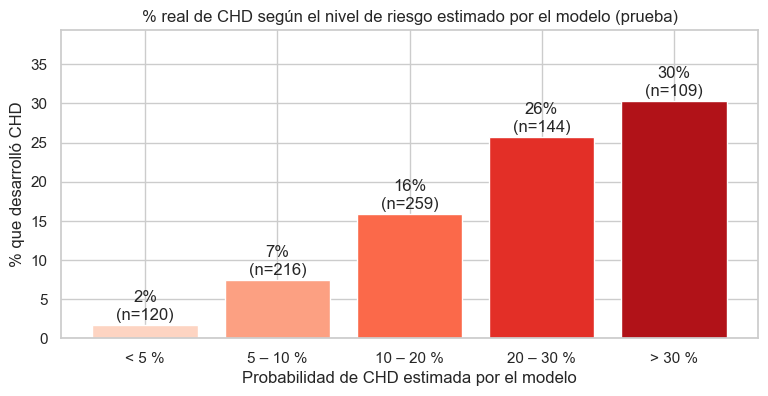

,pacientes,% que desarrolló CHD
estrato,,
< 5 %,120,1.667
5 – 10 %,216,7.407
10 – 20 %,259,15.830
20 – 30 %,144,25.694
> 30 %,109,30.275


In [39]:
# Estratificación del riesgo: ¿los pacientes con mayor probabilidad realmente enferman más?
estratos = pd.cut(prob_final, bins=[0, 0.05, 0.10, 0.20, 0.30, 1.0],
                  labels=['< 5 %', '5 – 10 %', '10 – 20 %', '20 – 30 %', '> 30 %'])
tabla_estratos = pd.DataFrame({'estrato': estratos, 'real': y_test.values}).groupby('estrato', observed=False)['real'].agg(['count', 'mean'])
tabla_estratos.columns = ['pacientes', '% que desarrolló CHD']
tabla_estratos['% que desarrolló CHD'] *= 100

tabla_estratos['% que desarrolló CHD'] = tabla_estratos['% que desarrolló CHD'].fillna(0)

plt.figure(figsize=(9, 4))
barras = plt.bar(tabla_estratos.index.astype(str), tabla_estratos['% que desarrolló CHD'],
                 color=sns.color_palette('Reds', len(tabla_estratos)))
plt.bar_label(barras, labels=[f'{v:.0f}%\n(n={n})' for v, n in zip(tabla_estratos['% que desarrolló CHD'], tabla_estratos['pacientes'])], padding=2)
plt.title('% real de CHD según el nivel de riesgo estimado por el modelo (prueba)')
plt.xlabel('Probabilidad de CHD estimada por el modelo'); plt.ylabel('% que desarrolló CHD')
plt.ylim(0, max(tabla_estratos['% que desarrolló CHD'].max() * 1.3, 10))
guardar_figura('15_estratos_riesgo')
plt.show()
tabla_estratos


**Interpretación de los resultados en el conjunto de prueba** (848 pacientes, 129 con CHD):

| | Modelo base | Modelo final (umbral 0.12) |
|---|---|---|
| Pacientes con CHD detectados | 10 de 129 | **103 de 129** |
| Pacientes con CHD no detectados (FN) | 119 | **26** |
| Falsas alarmas (FP) | 6 | 354 |
| Sensibilidad | 7.8 % | **79.8 %** |
| Especificidad | 99.2 % | 50.8 % |
| Precisión | 62.5 % | 22.5 % |
| ROC-AUC | 0.713 | 0.713 |

1. **El modelo final detecta a 8 de cada 10 pacientes que desarrollarán CHD**, contra menos de 1 de cada 10 del modelo base. Los casos no detectados bajan de 119 a 26.
2. **El costo son más falsas alarmas.** De los pacientes marcados como "en riesgo", el 22.5 % desarrolla CHD, contra 15.2 % de la población general: el grupo señalado concentra **1.5 veces más** casos que la población. En una herramienta de **tamizaje** (que prioriza a quién evaluar con más detalle), este costo es aceptable: un falso positivo implica estudios adicionales; un falso negativo, un infarto no prevenido.
3. **No hay sobreajuste:** el ROC-AUC en validación cruzada (0.730) y en prueba (0.713) son muy similares.
4. **Las probabilidades son confiables (calibración):** en la gráfica de estratos, el porcentaje real de CHD crece de forma consistente con la probabilidad estimada. Los pacientes con riesgo < 5 % enfermaron en 1.7 % de los casos; los de 5–10 %, en 7.4 %; los de 10–20 %, en 15.8 %; los de 20–30 %, en 25.7 %; y los de > 30 %, en 30.3 %. Esto valida usar la probabilidad del modelo en el dashboard.
5. **Contexto del desempeño:** un ROC-AUC de ~0.71 indica una capacidad de discriminación **moderada**, en línea con lo reportado para este conjunto de datos. El límite se debe principalmente a la información disponible: faltan variables relevantes como el colesterol HDL, los antecedentes familiares o la actividad física.


## 17. Interpretación del modelo (odds ratios)

### 17.1 Importancia relativa de las variables

Como las variables continuas están estandarizadas, los coeficientes del modelo final indican el efecto de **aumentar una desviación estándar** en cada variable (o de tener el factor, en las binarias). Esto permite compararlas entre sí.

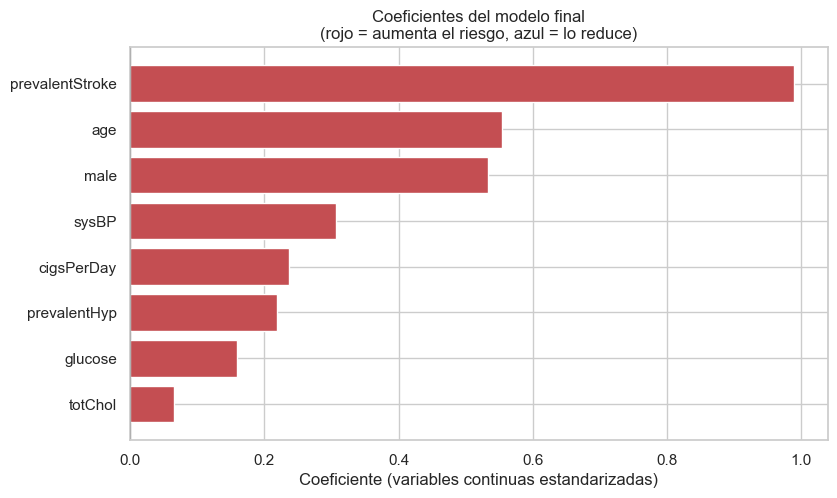

,variable,coeficiente,odds ratio
0,prevalentStroke,0.990,2.690
1,age,0.555,1.741
2,male,0.533,1.704
3,sysBP,0.307,1.359
4,cigsPerDay,0.236,1.266
5,prevalentHyp,0.219,1.245
6,glucose,0.160,1.173
7,totChol,0.065,1.067


In [40]:
modelo_lr = modelo_final.named_steps['modelo']
nombres_vars = modelo_final.named_steps['prep'].get_feature_names_out()

coeficientes = pd.DataFrame({'variable': nombres_vars, 'coeficiente': modelo_lr.coef_[0]})
coeficientes['odds ratio'] = np.exp(coeficientes['coeficiente'])
coeficientes = coeficientes.sort_values('coeficiente')

plt.figure(figsize=(9, 0.45 * len(coeficientes) + 1.5))
colores = [COLOR_CHD if c > 0 else COLOR_SANO for c in coeficientes['coeficiente']]
plt.barh(coeficientes['variable'], coeficientes['coeficiente'], color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Coeficientes del modelo final\n(rojo = aumenta el riesgo, azul = lo reduce)')
plt.xlabel('Coeficiente (variables continuas estandarizadas)')
guardar_figura('16_coeficientes')
plt.show()
coeficientes.sort_values('coeficiente', ascending=False).reset_index(drop=True)

### 17.2 Odds ratios en unidades originales

Para una interpretación clínica más intuitiva, se ajusta el mismo modelo con `statsmodels` sobre las variables **sin estandarizar** (en sus unidades originales), lo que permite obtener los **odds ratios con intervalos de confianza al 95 %** y sus valores p.

Para las variables continuas se reporta el efecto de un incremento clínicamente relevante (p. ej. 10 años de edad o 10 mmHg de presión), calculado como $e^{\beta \cdot \Delta}$.

In [41]:
X_or = X_train[VARIABLES_FINALES].astype(float)
if 'education' in VARIABLES_FINALES:
    X_or = pd.get_dummies(X_or, columns=['education'], drop_first=True, dtype=float)
logit_final = sm.Logit(y_train.values, sm.add_constant(X_or)).fit(disp=0)

incrementos = {'age': 10, 'cigsPerDay': 10, 'totChol': 40, 'sysBP': 20, 'diaBP': 10, 'BMI': 5, 'heartRate': 10, 'glucose': 20}
ic = logit_final.conf_int()
filas = []
for var in logit_final.params.index.drop('const'):
    delta = incrementos.get(var, 1)
    filas.append({
        'variable': var,
        'incremento': f'+{delta}' if var in incrementos else 'tener el factor (1 vs 0)',
        'odds ratio': np.exp(logit_final.params[var] * delta),
        'IC 95% inferior': np.exp(ic.loc[var, 0] * delta),
        'IC 95% superior': np.exp(ic.loc[var, 1] * delta),
        'valor p': logit_final.pvalues[var],
    })
tabla_or = pd.DataFrame(filas).sort_values('odds ratio', ascending=False).reset_index(drop=True)
tabla_or['cambio en los odds'] = [f'{(o - 1) * 100:+.0f}%' for o in tabla_or['odds ratio']]
tabla_or

,variable,incremento,odds ratio,IC 95% inferior,IC 95% superior,valor p,cambio en los odds
0,prevalentStroke,tener el factor (1 vs 0),3.461,1.296,9.240,0.013,+246%
1,age,+10,1.924,1.686,2.194,0.000,+92%
2,male,tener el factor (1 vs 0),1.740,1.400,2.162,0.000,+74%
3,sysBP,+20,1.320,1.176,1.482,0.000,+32%
4,prevalentHyp,tener el factor (1 vs 0),1.262,0.960,1.659,0.096,+26%
5,cigsPerDay,+10,1.217,1.119,1.323,0.000,+22%
6,glucose,+20,1.168,1.081,1.262,0.000,+17%
7,totChol,+40,1.064,0.969,1.168,0.192,+6%


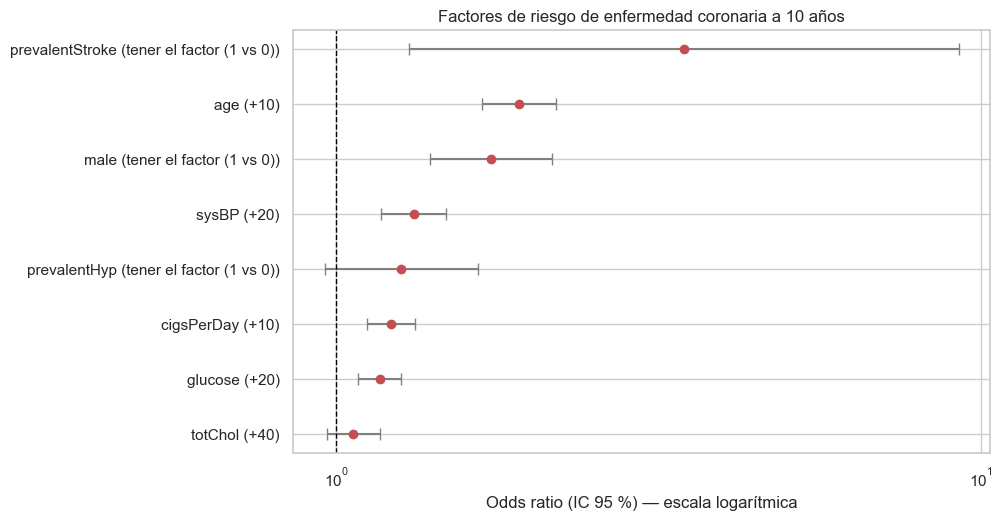

In [42]:
orden = tabla_or.sort_values('odds ratio')
etiquetas = [f"{v} ({inc})" for v, inc in zip(orden['variable'], orden['incremento'])]
plt.figure(figsize=(9, 0.5 * len(orden) + 1.5))
plt.errorbar(orden['odds ratio'], range(len(orden)),
             xerr=[orden['odds ratio'] - orden['IC 95% inferior'], orden['IC 95% superior'] - orden['odds ratio']],
             fmt='o', color=COLOR_CHD, ecolor='gray', capsize=4)
plt.axvline(1, color='black', linestyle='--', linewidth=1)
plt.yticks(range(len(orden)), etiquetas)
plt.xlabel('Odds ratio (IC 95 %) — escala logarítmica'); plt.xscale('log')
plt.title('Factores de riesgo de enfermedad coronaria a 10 años')
guardar_figura('17_odds_ratios')
plt.show()


**Interpretación de los factores de riesgo** (manteniendo constantes las demás variables):

| Factor | Efecto sobre los odds de desarrollar CHD a 10 años |
|---|---|
| **Derrame cerebral previo** | **×3.5** (+246 %). Es el mayor efecto, pero con un intervalo muy amplio (1.3 – 9.2) porque solo 25 pacientes tienen este antecedente. |
| **Edad** (+10 años) | **×1.9** (+92 %). Cada década casi duplica los odds. |
| **Sexo masculino** | **×1.7** (+74 %) respecto a las mujeres. |
| **Presión sistólica** (+20 mmHg) | **×1.3** (+32 %). |
| **Hipertensión** | ×1.3 (+26 %). No es significativa (p = 0.096) porque gran parte de su efecto ya lo captura la presión sistólica. |
| **Cigarrillos por día** (+10) | **×1.2** (+22 %). Fumar una cajetilla diaria (20 cigarrillos) implica ≈ ×1.48 (+48 %). |
| **Glucosa** (+20 mg/dL) | **×1.2** (+17 %). |
| **Colesterol total** (+40 mg/dL) | ×1.06 (+6 %). No es significativo en este conjunto. |

- **Todos los odds ratios son mayores a 1:** todas las variables seleccionadas son factores de **riesgo**; ninguna es protectora.
- **Factores no modificables:** edad, sexo y derrame previo. Permiten identificar a quién vigilar.
- **Factores modificables:** tabaquismo, presión arterial, glucosa y colesterol. Son el blanco de las acciones preventivas: reducir 20 mmHg la presión sistólica o dejar de fumar una cajetilla diaria disminuye los odds de forma comparable a "rejuvenecer" unos 4 y 6 años, respectivamente.
- **Nota:** el odds ratio no es exactamente el riesgo relativo, pero se aproxima a él cuando el evento es poco frecuente.

El orden de importancia coincide con el de los coeficientes estandarizados de la sección 17.1 (edad, sexo y presión sistólica, después del derrame previo) y con lo observado en el EDA.


## 18. Exportación del modelo y de los datos

Se guardan los artefactos que utilizará el **dashboard**:

- `models/modelo_regresion_logistica.pkl`: el pipeline completo (preprocesamiento + modelo), el umbral elegido, las variables de entrada y los valores de imputación.
- `models/metricas.json`: métricas de evaluación en el conjunto de prueba.
- `data/processed/framingham_limpio.csv`: el conjunto completo ya imputado (con los valores aprendidos del entrenamiento), para las visualizaciones del dashboard.
- `data/processed/predicciones_prueba.csv`: probabilidades y predicciones sobre el conjunto de prueba.

In [43]:
import joblib
import json

Path('models').mkdir(exist_ok=True)
Path('data/processed').mkdir(parents=True, exist_ok=True)

# Modelo final reentrenado con todo el conjunto de entrenamiento (GridSearchCV ya lo hace con refit=True)
artefacto = {
    'pipeline': modelo_final,
    'umbral': UMBRAL,
    'variables': VARIABLES_FINALES,
    'imputacion': {
        'cigsPerDay_fumadores': float(imputer_cigs.statistics_[0]),
        **{c: float(v) for c, v in zip(cols_moda, imputer_moda.statistics_)},
        **{c: float(v) for c, v in zip(cols_mediana, imputer_mediana.statistics_)},
    },
    'hiperparametros': busqueda.best_params_,
    'estrategia_balanceo': ESTRATEGIA,
}
joblib.dump(artefacto, 'models/modelo_regresion_logistica.pkl')

metricas_export = {
    'umbral': UMBRAL,
    'prueba': {k: float(v) for k, v in tabla_final[f'Modelo final (umbral {UMBRAL})'].items()},
    'base': {k: float(v) for k, v in metricas_base.items()},
    'roc_auc_cv': float(busqueda.best_score_),
    'matriz_confusion': confusion_matrix(y_test, pred_final).tolist(),
    'odds_ratios': tabla_or[['variable', 'incremento', 'odds ratio', 'IC 95% inferior', 'IC 95% superior', 'valor p']].to_dict(orient='records'),
}
with open('models/metricas.json', 'w', encoding='utf-8') as f:
    json.dump(metricas_export, f, ensure_ascii=False, indent=2)

# Conjunto completo limpio (para visualización en el dashboard)
datos_limpios = pd.concat([X_train.assign(TenYearCHD=y_train, conjunto='entrenamiento'),
                           X_test.assign(TenYearCHD=y_test, conjunto='prueba')]).sort_index()
datos_limpios.to_csv('data/processed/framingham_limpio.csv', index=False)

pd.DataFrame({'real': y_test.values, 'probabilidad': prob_final, 'prediccion': pred_final},
             index=X_test.index).to_csv('data/processed/predicciones_prueba.csv')

print('Archivos generados:')
for p in ['models/modelo_regresion_logistica.pkl', 'models/metricas.json',
          'data/processed/framingham_limpio.csv', 'data/processed/predicciones_prueba.csv']:
    print(f'  {p}  ({Path(p).stat().st_size / 1024:,.1f} KB)')

Archivos generados:
  models/modelo_regresion_logistica.pkl  (4.0 KB)
  models/metricas.json  (2.7 KB)
  data/processed/framingham_limpio.csv  (306.8 KB)
  data/processed/predicciones_prueba.csv  (24.5 KB)


### Prueba del modelo guardado con pacientes nuevos

Se carga el modelo desde el archivo (como lo hará el dashboard) y se calcula el riesgo de dos pacientes hipotéticos.

In [44]:
cargado = joblib.load('models/modelo_regresion_logistica.pkl')

pacientes = pd.DataFrame([
    {'male': 0, 'age': 42, 'education': 3, 'currentSmoker': 0, 'cigsPerDay': 0, 'BPMeds': 0, 'prevalentStroke': 0,
     'prevalentHyp': 0, 'diabetes': 0, 'totChol': 190, 'sysBP': 115, 'diaBP': 75, 'BMI': 23, 'heartRate': 70, 'glucose': 80},
    {'male': 1, 'age': 63, 'education': 1, 'currentSmoker': 1, 'cigsPerDay': 25, 'BPMeds': 1, 'prevalentStroke': 0,
     'prevalentHyp': 1, 'diabetes': 1, 'totChol': 280, 'sysBP': 170, 'diaBP': 100, 'BMI': 31, 'heartRate': 85, 'glucose': 150},
], index=['Paciente A (perfil saludable)', 'Paciente B (múltiples factores)'])

probabilidad = cargado['pipeline'].predict_proba(pacientes[cargado['variables']])[:, 1]
pd.DataFrame({'probabilidad de CHD a 10 años': probabilidad,
              'clasificación': np.where(probabilidad >= cargado['umbral'], 'RIESGO ALTO', 'riesgo bajo')},
             index=pacientes.index)

,probabilidad de CHD a 10 años,clasificación
Paciente A (perfil saludable),0.037,riesgo bajo
Paciente B (múltiples factores),0.689,RIESGO ALTO


## 19. Conclusiones, limitaciones y recomendaciones

### Conclusiones


1. **Se completó el ciclo de datos completo:** obtención del conjunto del Framingham Heart Study, extracción y revisión de calidad, limpieza sin fuga de datos, análisis exploratorio, modelado con Regresión Logística, evaluación, interpretación y exportación para el dashboard.
2. **La calidad de los datos era buena:** sin duplicados, con 13.7 % de registros con algún faltante (resuelto con imputación por tipo de variable) y valores extremos clínicamente válidos.
3. **El desbalance de clases (15 % positivos) era el principal reto.** Un modelo ingenuo alcanza 85 % de exactitud sin detectar casi a nadie. Se demostró que el balanceo con SMOTE o con pesos no mejora la discriminación y que, en cambio, descalibra las probabilidades. Por eso se trató el desbalance **ajustando el umbral de decisión**.
4. **El modelo final es simple e interpretable:** una Regresión Logística con **8 variables** (edad, sexo, cigarrillos por día, presión sistólica, glucosa, derrame previo, hipertensión y colesterol), que mantiene el mismo desempeño que el modelo con las 15.
5. **Desempeño en datos no vistos:** detecta al **79.8 %** de los pacientes que desarrollarán CHD (contra 7.8 % del modelo base), con un ROC-AUC de **0.713**, sin sobreajuste y con probabilidades bien calibradas.
6. **Factores de riesgo principales:** la edad (cada 10 años ×1.9), el sexo masculino (×1.7), el antecedente de derrame (×3.5), la presión sistólica, el tabaquismo y la glucosa. Varios de ellos son **modificables**, lo que abre espacio para la prevención.


### Limitaciones


- **Representatividad:** los datos provienen de una sola ciudad de EE. UU., con una población mayoritariamente de origen europeo y recolectada hace varias décadas. Antes de aplicarlo a otra población (por ejemplo, la mexicana), el modelo debe **validarse externamente**.
- **Capacidad de discriminación moderada (AUC ≈ 0.71):** el modelo genera muchas falsas alarmas (precisión de 22.5 %). Es una herramienta de **tamizaje y apoyo**, no de diagnóstico.
- **Variables ausentes:** no incluye factores importantes como el colesterol HDL/LDL, los antecedentes familiares, la actividad física, la dieta o el estrés.
- **Imputación:** el 9 % de los valores de glucosa se reemplazó por la mediana, lo que reduce artificialmente su variabilidad.
- **Pocos casos de derrame previo** (25 pacientes): el efecto estimado de este factor tiene mucha incertidumbre (IC 95 %: 1.3 – 9.2).
- **Supuestos del modelo:** la Regresión Logística asume una relación lineal entre cada variable y el logaritmo de los odds, y no considera interacciones entre factores (por ejemplo, edad × tabaquismo).
- **Tamaño del conjunto de prueba:** con 129 casos positivos en prueba, las métricas tienen cierta variabilidad; por eso se complementaron con validación cruzada.


### Recomendaciones y trabajo futuro


- **Uso como herramienta de tamizaje:** aplicar el modelo para **priorizar** qué pacientes deben recibir una evaluación cardiológica más detallada, no para diagnosticar.
- **Enfocar la prevención en los factores modificables:** control de la presión arterial, abandono del tabaco y control de la glucosa y el colesterol, sobre todo en hombres y en personas mayores de 50 años.
- **El umbral es ajustable:** según los recursos disponibles, se puede subir el umbral (menos falsas alarmas y menor sensibilidad) o bajarlo (más detección). El dashboard permite visualizar ese equilibrio.
- **Trabajo futuro:**
  - incorporar más variables clínicas (HDL, LDL, antecedentes familiares, actividad física);
  - probar interacciones y transformaciones no lineales dentro de la Regresión Logística;
  - validar el modelo con datos de otra población;
  - actualizarlo periódicamente con datos nuevos.


## 20. Referencias

1. Framingham Heart Study. *National Heart, Lung, and Blood Institute & Boston University.* https://www.framinghamheartstudy.org/
2. Dataset: *Logistic regression to predict heart disease* (framingham.csv). Kaggle. https://www.kaggle.com/datasets/dileep070/heart-disease-prediction-using-logistic-regression
3. Organización Mundial de la Salud (2021). *Enfermedades cardiovasculares* — Nota descriptiva. https://www.who.int/es/news-room/fact-sheets/detail/cardiovascular-diseases-(cvds)
4. D'Agostino, R. B., et al. (2008). General cardiovascular risk profile for use in primary care: the Framingham Heart Study. *Circulation*, 117(6), 743–753.
5. Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied Logistic Regression* (3rd ed.). Wiley.
6. Chawla, N. V., et al. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357.
7. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830. https://scikit-learn.org/
8. Documentación de `imbalanced-learn`: https://imbalanced-learn.org/ y de `statsmodels`: https://www.statsmodels.org/